In [1]:
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Memeriksa path dataset yang ada di Kaggle

##### Code ini buat memeriksa apakah input yang terdapat di Kaggle sudah memiliki dataset atau belum.

In [2]:
import os

print("Daftar dataset di /kaggle/input:")
print(os.listdir('/kaggle/input'))

Daftar dataset di /kaggle/input:
['datasets']


# Import library yang dibutuhkan

##### Code ini untuk mengimport beberapa library yang akan dibutuhkan dalam load dataset, pre-processing, training model hingga evaluasi model

In [3]:
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import tensorflow as tf

# library buat pre-processing
from tensorflow.keras import Sequential
from tensorflow.io import read_file
from tensorflow.image import decode_jpeg, resize
from tensorflow import cast, float32, one_hot
from tensorflow.data import AUTOTUNE

# library buat class ConvolutionalBlockAttentionModule
from tensorflow import reduce_mean, reduce_max
from tensorflow import concat


# library buat training model
from tensorflow import keras
from tensorflow.keras.applications import ResNet50 as KerasResNet50
from tensorflow.keras.applications import ResNet152V2 as KerasResNet152V2
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import(
    Input,
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    GlobalMaxPooling2D,
    Reshape,
    Multiply,
    Add,
    Activation
)

# library buat testing atau evaluasi model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.models import load_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

# library buat visualisasi
from matplotlib.pyplot import (
    figure,
    show,
    subplot,
    subplots,
    suptitle,
    tight_layout
)
from seaborn import heatmap

# library buat perhitungan dan analisis data
from numpy import(
    argmax,
    array,
    clip,
    divide,
    isclose,
    prod,
    uint8,
    zeros_like
)

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)

TensorFlow : 2.20.0
Keras      : 3.13.2


# Load Dataset

In [4]:
path_dataset = '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026'
path_dataset

'/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026'

# Konfigurasi buat dataset image

##### Beberapa konfigurasi yang diperlukan dalam menentukan ukuran dataset image seperti 
##### A. IMAGE_SIZE, berguna untuk menentukan ukuran (lebar dan tinggi dalam piksel) dimensi gambar yang akan dimasukkan ke dalam model.
##### B. BATCH_SIZE, berguna untuk menentukan jumlah sampel gambar yang akan diproses oleh model dalam satu kali jalan (satu iterasi) sebelum model memperbarui bobotnya (weight update).
##### C. SEED, berguna untuk menentukan angka acak awal (random state) agar proses pengacakan data menghasilkan outpu yang konsisten setiap kali code dijalankan.
##### D. train_size, berguna untuk menentukan proporsi data yang akan digunakan untuk pelatihan atau training model (80%).
##### E. val_size, berguna untuk menentukan proporsi data yang akan digunakan untuk validasi (10%).
##### F. test_size, berguna untuk menentukan proporsi data yang akan digunakan untuk pengujian atau testing model (10%).

In [5]:
# configuration
IMAGE_SIZE = (224,224)
BATCH_SIZE = 32
SEED       = 42
train_size = 0.80
val_size   = 0.10
test_size  = 0.10

# Create Dataset

##### Dalam membuat dataset, terdapat beberapa tahapan yang akan dilakukan, diantaranya adalah:
##### A. Membuat class CreateCocoaDataset
##### B. Membuat instance dataset_manager
##### C. Memanggil method load_dataset
##### D. Memanggil method count_image_for_each_class
##### E. Memanggil method split_dataset
##### F. Create tensorflow dataset untuk resnet50
##### G. Create tensorflow dataset untuk resnet152v2

## A. Membuat Class CreateCocoaDataset

Dalam class CreateCocoaDataset berikut, terdapat beberapa method yang memiliki kegunaan masing-masing, diantaranya adalah:
1. **Method __init__**, berguna untuk menginisialisasi parameter dasar, mendefinisikan nama-nama kelas kakao dataset, membuat variable penampung data serta menyusun urutan lapisan augmentasi data.
2. **Method load_dataset**, berguna untuk membaca berkas gambar dari folder penyimpanan yang terdapat di dataset.
3. **Method count_image_for_each_class**, berguna untuk menghitung total jumlah gambar yang tersedia untuk setiap kelas kakao dataset.
4. **Method split_dataset**, berguna untuk membagi dataset menjadi 3 bagian, yaitu training (80%), validation (10%) dan testing (10%).
5. **Method preprocess_image**, berguna untuk mengubah gambar mentah yang terdapat di dataset agar dapat diproses oleh model. method preprocess_image terdapat beberapa tahapan seperti:
* **a)** membaca (read) file berkas.
* **b)** mengubah gambar menjadi tensor number (array), dengan format warna RGB (Red, Green, Blue) dan tensor 3 Dimensi dengan struktur [tinggi, lebar, saluran warna).
* **c)** mengubah ukuran menjadi 224x224 piksel agar sesuai dengan ukuran input model deep learning.
* **d)** mengubah tipe data cast dari tensor number (array) ke float32 agar memudahkan dalam proses normalisasi.
* **e)** menerapkan augmentasi data, dengan kondisi dimana dataset tersebut merupakan data training. jadi, yang di augmentasi merupakan data training. augmentasi data diperlukan untuk mencegah overfitting dan meningkatkan kemampuan generalisasi model deep learning.
* **f)** melakukan normalisasi piksel spesifik sesuai ukuran arsitektur model resnet50 atau resnet152v2.
* **g)** mengubah label angka kelas menjadi format One-Hot Encoding [0, 1, 2, 3] agar menghindari asumsi "Urutan Nilai" (ordinal bias) pada model deep learning.
6. **Method create_dataset_tensorflow**, berguna untuk mengatur proses loading gambar secara paralel (map), pengacakan urutan data (shuffle), pengelompokan data (batch) serta mempersiapkan data berikutnya di memori sebelum model memintanya (prefetch).
7. **Method get_train_val_test**, berguna untuk pintu keluar utama dalma mengambil data akhir serta menghasilkan tiga objek dataset (train, val dan test) yang siap dimasukkan ke tahapan training model.
8. **Method visualize_augmented_data**, berguna untuk menampilkan contoh visualisasi gambar training yang telah melewati proses augmentasi data.

In [6]:
class CreateCocoaDataset:
    def __init__(
        self, 
        dataset_path, 
        image_size=(224, 224), 
        batch_size=32, 
        train_size=0.80, 
        val_size=0.10, 
        test_size=0.10, 
        seed=42
    ):
        self.dataset_path = dataset_path
        self.image_size = image_size
        self.batch_size = batch_size
        self.train_size = train_size
        self.val_size = val_size
        self.test_size = test_size
        self.seed = seed

        self.class_names = ["Busuk Buah", "Helopeltis", "Kakao Sehat", "Penggerek Buah Kakao"]
        self.class_mapping = {"Busuk Buah": 0, "Helopeltis": 1, "Kakao Sehat": 2, "Penggerek Buah Kakao": 3}
        self.image_paths = []
        self.labels = []

        self.X_train = None
        self.X_val = None
        self.X_test = None

        self.y_train = None
        self.y_val = None
        self.y_test = None

        # ==================================
        # AUGMENTASI DATA PADA DATA TRAINING
        # RANDOM FLIP, RANDOM ROTATION, RANDOM ZOOM, RANDOM TRANSLATION, AND RANDOM CONTRAST
        # ==================================
        self.data_augmentation = Sequential([
            layers.RandomFlip(mode="horizontal", seed=self.seed),
            layers.RandomRotation(factor=0.0417, seed=self.seed),
            layers.RandomZoom(height_factor=0.10, width_factor=0.10, seed=self.seed),
            layers.RandomTranslation(height_factor=0.05,width_factor=0.05, seed=self.seed),
            layers.RandomContrast(factor=0.10, seed=self.seed)
        ], name="cocoa_data_augmentation")

    # method load dataset
    def load_dataset(self):
        valid_extension = (".jpg", ".jpeg")

        self.image_paths = []
        self.labels = []

        print("Class Mapping: ")
        for class_name, label in self.class_mapping.items():
            print(f"{label} -> {class_name}")
            
        print("\nMembaca Dataset: ")
        for class_name in self.class_names:
            class_path = os.path.join(self.dataset_path, class_name)
            if not os.path.isdir(class_path):
                raise FileNotFoundError(f"Folder tidak ditemukan: {class_path}")

            print(f"Membaca Kelas: {class_name}")
            for filename in os.listdir(class_path):
                if filename.lower().endswith(valid_extension):
                    image_path = os.path.join(class_path, filename)
                    self.image_paths.append(image_path)
                    self.labels.append(self.class_mapping[class_name])

        self.image_paths = array(self.image_paths)
        self.labels = array(self.labels)

        print("Dataset berhasil dimuat!")
        print(f"Total Gambar: {len(self.image_paths)}")
        print(f"Total Kelas: {len(self.class_names)}")
        
        return (self.image_paths, self.labels)

    # method counting the images for each class
    def count_image_for_each_class(self):
        class_counts = []
        for class_name in self.class_names:
            label = self.class_mapping[class_name]
            count = sum(self.labels == label)

            class_counts.append({
                "Kelas": class_name,
                "Label" : label,
                "Jumlah Gambar" : int(count)
            })
        
        return pd.DataFrame(class_counts)

    # method split dataset
    def split_dataset(self):
        total_ratio = (
            self.train_size + self.val_size + self.test_size
        )

        if not np.isclose(total_ratio, 1.0):
            raise ValueError("Total Proporsi Train, Validation dan Test Tidak Boleh Kurang Dari 1.0")

        # 80% Train
        # 20% Temporary
        self.X_train, X_temp, \
        self.y_train, y_temp = train_test_split(
            self.image_paths,
            self.labels,
            test_size=self.val_size + self.test_size,
            stratify = self.labels,
            random_state = self.seed
        )

        # Temporary -> Validation + Test
        # Validation 10%
        # Test 10%
        relative_test_size = (
            self.test_size / (self.val_size + self.test_size)
        )

        self.X_val, self.X_test, \
        self.y_val, self.y_test = train_test_split(
            X_temp,
            y_temp,
            test_size=relative_test_size,
            stratify=y_temp,
            random_state=self.seed
        )

        print("\nPembagian dataset:")
        print(f"Train      : {len(self.X_train)}")
        print(f"Validation : {len(self.X_val)}")
        print(f"Test       : {len(self.X_test)}")

        return None

    # method preprocessing
    def preprocess_image(self, image_path, label, training=False, model_type="resnet50"):
        
        # read file
        image = read_file(image_path)

        # change image to tensor number (array)
        image = decode_jpeg(image, channels=3)

        # resize 224 x 224
        image = resize(image, self.image_size)

        # change type data cast from tensor number (array) to float32
        image = cast(image, float32)

        # data augmentation if training = true
        if training:
            image=self.data_augmentation(image, training=True)

        # Preprocessing sesuai arsitektur resnet50 atau resnet152v2
        if model_type == "resnet50":
            image = tf.keras.applications.resnet50.preprocess_input(image)
        elif model_type == "resnet152v2":
            image = tf.keras.applications.resnet_v2.preprocess_input(image)
        else:
            raise ValueError(f"Model type tidak dikenal: {model_type}. Gunakan 'resnet50' atau 'resnet152v2'.")

        # One-hot encoding label
        label = one_hot(label, depth=len(self.class_names))

        return image, label

    # method create tensorflow dataset
    def create_dataset_tensorflow(self, image_paths, labels, shuffle=False, training=False, model_type="resnet50"):
        dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
        dataset = dataset.map(lambda image_path, label: self.preprocess_image(image_path, label, training=training, model_type=model_type), num_parallel_calls=AUTOTUNE)

        if shuffle:
            dataset = dataset.shuffle(buffer_size=min(len(image_paths), 1000), seed=self.seed, reshuffle_each_iteration=True)

        dataset = dataset.batch(self.batch_size)
        dataset = dataset.prefetch(AUTOTUNE)

        return dataset

    # method get train, validation and test
    def get_train_val_test(self, model_type="resnet50"):
        train_dataset = self.create_dataset_tensorflow(self.X_train, self.y_train, shuffle=True, training=True, model_type=model_type)
        val_dataset = self.create_dataset_tensorflow(self.X_val, self.y_val, shuffle=False, training=False, model_type=model_type)
        test_dataset = self.create_dataset_tensorflow(self.X_test, self.y_test, shuffle=False, training=False, model_type=model_type)

        return(train_dataset, val_dataset, test_dataset)

    # method visualize augmented data
    def visualize_augmented_data(self, train_dataset):
        figure(figsize=(12, 8))

        for images, labels in train_dataset.take(1):
            for i in range(min(8, len(images))):
                ax = subplot(2, 4, i+1)

                image = images[i].numpy()

                # pembalikan preprocess ResNet50 (Mode Caffe)
                # BGR -> RGB
                image = image[..., ::-1]

                # ditambahkan kembali dengan Mean ImageNet
                mean = array([103.939, 116.779, 123.68])
                image = image + mean
                image = clip(image, 0, 255).astype(uint8)

                ax.imshow(image)
                label = argmax(labels[i].numpy())
                ax.set_title(self.class_names[label])
                ax.axis("off")

        suptitle("Visualisasi Gambar Training Setelah Augmentasi", fontsize=16)
        tight_layout()
        show()

## B. Membuat instance dataset_manager

Instance ini diperlukan untuk menampung objek baru dengan nama dataset_manager yang dicetak berdasarkan class CreateCocoaDataset.

In [7]:
dataset_manager = CreateCocoaDataset(
    dataset_path=path_dataset,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    train_size=train_size,
    val_size=val_size,
    test_size=test_size,
    seed=SEED
)

I0000 00:00:1792047808.693012      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792047808.696214      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## C. Memanggil method load_dataset

dengan memanggil method load_dataset melalui instance dataset_manager, code akan melakukan:
1. memetakan label penyakit kakao (0 - 3).
2. membaca berkas gambar yang berformat .jpg atau .jpeg.
3. memasukkan jalur gambar (image paths) dan labelnya ke dalam variable objek.
4. menampilkan statistik ringkas total gambar dan kelas yang berhasil dimuat di terminal.

In [8]:
# load dataset
dataset_manager.load_dataset()

Class Mapping: 
0 -> Busuk Buah
1 -> Helopeltis
2 -> Kakao Sehat
3 -> Penggerek Buah Kakao

Membaca Dataset: 
Membaca Kelas: Busuk Buah
Membaca Kelas: Helopeltis
Membaca Kelas: Kakao Sehat
Membaca Kelas: Penggerek Buah Kakao
Dataset berhasil dimuat!
Total Gambar: 6992
Total Kelas: 4


(array(['/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Busuk Buah/train_dataset_2_busuk_buah_131.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Busuk Buah/train_dataset_1_busuk_buah_324.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Busuk Buah/train_dataset_1_busuk_buah_368.jpg',
        ...,
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Penggerek Buah Kakao/train_dataset_1_penggerek_buah_kakao_314.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Penggerek Buah Kakao/train_dataset_1_penggerek_buah_kakao_531.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Penggerek Buah Kakao/train_dataset_2_pbk_239.jpg'],
       dtype='<U129'),
 array([0, 0, 0, ..., 3, 3, 3]))

## D. Memanggil method count_image_for_each_class

dengan memanggil method count_image_for_each_class melalui instance dataset_manager, code akan melakukan:
1. penyaringan data dengan melihat variable self.labels.
2. mengitung banyaknya gambar yang memiliki label 0 (busuk buah), label 1 (helopeltis), label 2 (kakao sehat) dan label 3 (penggerek buah kakao).
3. setelah menghitung banyaknya gambar yang dimiliki oleh setiap label, hasil hitungan tersebut kemudian dikumpulkan dan diubah menjadi objek Pandas DataFrame.

In [9]:
# count image for each class
dataset_manager.count_image_for_each_class()

,Kelas,Label,Jumlah Gambar
0,Busuk Buah,0,1748
1,Helopeltis,1,1748
2,Kakao Sehat,2,1748
3,Penggerek Buah Kakao,3,1748


## E. Memanggil method split_dataset

dengan memanggil method split_dataset melalui instance dataset_manager, code akan melakukan:
1. memeriksa apakah total penjumlahan dari train_size, val_size dan test_size berjumlah 1.0 (100%).
2. pembagian data tahap pertama (train & temporary) dengan proporsi 80% untuk train dan 20% untuk temporary.
3. pembagian data tahap kedua dengan memecah data temporary menjadi data val dan data test dengan proporsi masing-masing sebesar 10%.

In [10]:
# split dataset
dataset_manager.split_dataset()


Pembagian dataset:
Train      : 5593
Validation : 699
Test       : 700


## F. Create tensorflow dataset untuk resnet50

code berikut akan membuat (create) tensorflow dataset untuk model resnet50, dengan melewati beberapa tahapan:
1. function get_train_val_test akan memanggil function internal sebanyak 3 kali untuk melakukan proses data train, valid dan test.
2. setiap gambar akan dibaca secara paralel dari penyimpanan dataset dan melewati function preprocess_image.
3. khusus untuk data training, urutan gambar akan diacak pada setiap epoch pelatihan agar model tidak menghafal urutan data.
4. gambar dikelompokkan ke dalam ukuran kelompok kecil berdasarkan konfigurasi yang ditentukan (32 Batch).
5. menggunakan fitur AUTOTUNE untuk mempersiapkan batch data berikutnya di memori saat model sedang menjalankan suatu batch data, sehingga proses pelatihan model menjadi jauh lebih cepat.

In [11]:
# create tensorflow dataset untuk resnet50
train_dataset_resnet50, val_dataset_resnet50, test_dataset_resnet50=(dataset_manager.get_train_val_test(model_type="resnet50"))

## G. Create tensorflow dataset untuk resnet152v2

code berikut akan membuat (create) tensorflow dataset untuk model resnet152v2 melalui pemanggilan method get_train_val_test, dengan melewati beberapa tahapan:
1. function get_train_val_test akan memanggil function internal sebanyak 3 kali untuk melakukan proses data train, valid dan test.
2. setiap gambar akan dibaca secara paralel dari penyimpanan dataset dan melewati function preprocess_image.
3. khusus untuk data training, urutan gambar akan diacak pada setiap epoch pelatihan agar model tidak menghafal urutan data.
4. gambar dikelompokkan ke dalam ukuran kelompok kecil berdasarkan konfigurasi yang ditentukan (32 Batch).
5. menggunakan fitur AUTOTUNE untuk mempersiapkan batch data berikutnya di memori saat model sedang menjalankan suatu batch data, sehingga proses pelatihan model menjadi jauh lebih cepat.

In [12]:
# create tensorflow dataset untuk resnet152v2
train_dataset_resnet152v2, val_dataset_resnet152v2, test_dataset_resnet152v2=(dataset_manager.get_train_val_test(model_type="resnet152v2"))

## H. Memanggil method visualize_augmented_data

dengan memanggil method visualize_augmented_data melalui instance dataset_manager, code akan melakukan visualisasi image setelah augmentasi pada data train model resnet50

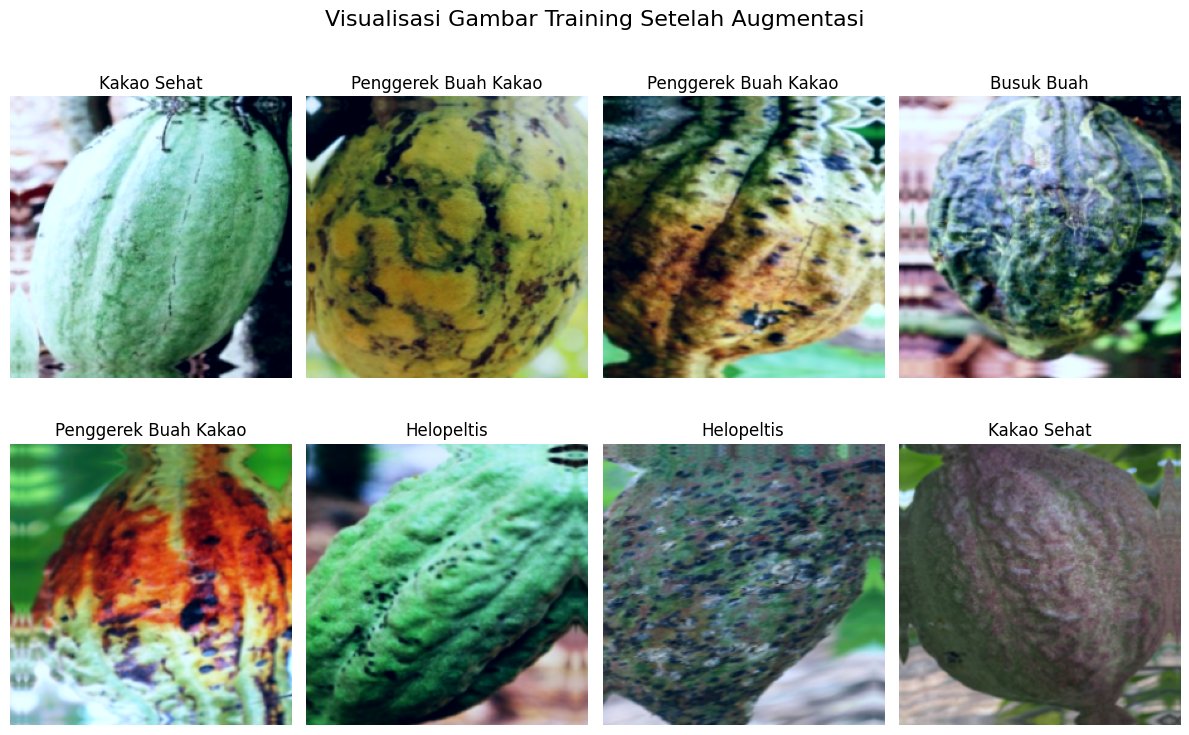

In [13]:
# Memanggil method visualisasi baru
dataset_manager.visualize_augmented_data(train_dataset_resnet50)

# Training Model

Dalam training model ini menggunakan beberapa model, diantaranya adalah ResNet50-CBAM, ResNet50 dan ResNet152V2. Dimana, disetiap modelnya dilakukan 2 tahapan, yaitu tahapan freeze backbone ResNet dan tahapan fine-tuning. 

## A. Konfigurasi Callback Masing-Masing Model

Terdapat beberapa Callback (sekumpulan fungsi otomtis yang berjalan di setiap akhir epoch selama proses pelatihan model berlangsung) yang diperlukan untuk training model, diantaranya adalah:
1) **Callback ModelCheckpoint** ===> digunakan untuk menyimpan bobot (weights) model terbaik secara otomatis ke dalam format file .keras. Terdapat beberapa parameter penting yang digunakan dalam Callback ModelCheckpoint seperti parameter **monitor="val_loss"** dan **mode="min"** untuk memantau nilai kerugian (loss) pada data validasi serta parameter **save_best_only=True** untuk memperbarui file .keras jika nilai val_loss di epoch terbaru lebih rendah dibandingkan dengan epoch sebelumnya.
2) **Callback EarlyStopping** ===> digunakan untuk menghentikan proses pelatihan model secara otomatis sebelum mendapati batas maksimal epoch jika model sudah tidak menunjukkan peningkatan performa lagi. Terdapat beberapa parameter penting yang digunakan dalam Callback EarlyStopping seperti **patience=7** untuk menghentikan pelatihan model jika selama 7 epoch berturut-turut nilai val_loss tidak kunjung turun serta parameter **restore_best_weights=True** untuk mengembalikan bobot model ke kondisi terbaiknya jika pelatihan model berhenti karena Callback EarlyStopping.
3) **Callback ReduceLROnPlateau** ===> digunakan untuk menurunkan nilai learning rate secara otomatis saat performa model mulai stagnan. Terdapat beberapa parameter penting yang digunakan dalam Callback ReduceLROnPlateau seperti parameter **patience=2** untuk kondisi dimana jika dalam 2 epoch berturut-turut nilai val_loss tidak kunjung turun, maka nilai learning rate saat itu akan dikalikan 0.5 (dari parameter **factor=0.5** == dipotong setengahnya) agar model bisa melangkah lebih hati-hati dalam mencari nilai optimal, serta parameter **min_lr=1e-7** untuk batas paling minimun yang akan digunakan dalam penurunan learning rate.


In [14]:
def create_callbacks(checkpoint_path):
    return [
        ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

In [15]:
callbacks_resnet50_cbam_tahap_1 = create_callbacks("best_resnet50_cbam_tahap_1.keras")
callbacks_resnet50_cbam_tahap_2 = create_callbacks("best_resnet50_cbam_tahap_2.keras")

callbacks_resnet50_tahap_1 = create_callbacks("best_resnet50_tahap_1.keras")
callbacks_resnet50_tahap_2 = create_callbacks("best_resnet50_tahap_2.keras")

callbacks_resnet152v2_tahap_1 = create_callbacks("best_resnet152v2_tahap_1.keras")
callbacks_resnet152v2_tahap_2 = create_callbacks("best_resnet152v2_tahap_2.keras")

## B. Model Arsitektur ResNet50-CBAM

Saat melakukan pelatihan pada model arsitektur ResNet50-CBAM, terdapat beberapa tahapan yang perlu dilakukan, diantaranya adalah:
1. Membuat class ConvolutionalBlockAttentionModule
2. Membuat class ResNet50CBAM
3. Membuat instance resnet50_cbam_builder
4. Memanggil method freeze_backbone
5. Melakukan Compile Model (Training ResNet50-CBAM Tahap 1)
6. Melakukan Training Model ResNet50CBAM Tahap 1
7. Melihat Plot Akurasi dan Loss Model pada Training ResNet50CBAM Tahap 1
8. Memanggil method unfreeze_top_stages
9. Melakukan Compile Model (Training Model ResNet50-CBAM Tahap 2)
10. Melakukan Training Model ResNet50CBAM Tahap 2
11. Melihat Plot Akurasi dan Loss Model pada Training ResNet50CBAM Tahap 2

### 1. Membuat class ConvolutionalBlockAttentionModule

Dalam class ConvolutionalBlockAttentionModule, terdapat beberapa method yang memiliki kegunaan masing-masing, diantaranya adalah:
1. **method __init__**, berguna untuk mengkonfigurasi parameter awal modul sebelum lapisan-lapisan di dalamnya dibangun. Terdapat beberapa parameter penting seperti **reduction_ratio=16** untuk menentukan rasio penyusutan dalam memperkecil jumlah channel pada jaringan saraf tiruan (MLP) agar dapat menghemat komputasi dan parameter **spatial_kernel_size=7** untuk menentukan ukuran filter atau jendela konvolusi (7x7) yang digunakna dalam mendeteksi hubungan spasial atau lokasi pada gambar.
2. **method build**, berguna untuk membangun dan menginisialisasi lapisan-lapisan (layers) berbobot yang membutuhkan kepastian ukuran input gambar (input_shape) secara otomatis saat model pertama kali dijalankan. Terdapat beberapa komponen utama seperti **self.shared_dense_1 & self.shared_dense_2** yang merupakan dua lapisan Dense (MLP) yang dipakai secara bersama (shared) untuk mengekstrak informasi penting antar channel, serta komponen **self.spatial_conv** yang merupakan lapisan konvolusi 2D dengan fungsi aktivasi Sigmoid untuk menghasilkan peta perhatian lokasi (koordinat piksel mana yang penting).
3. **method channel_attention**, berguna untuk menjalankan mekanisme Channel Attention yang berfugsi dalam mencari tahu fitur atau karakteristikapa yang paling menonjol (semisal warna busuk buah, corak bercak serangan hama atau tekstur dari kulit buah kakao sehat). **Cara Kerja Channel Attention** => Melakukan Global Average Pooling dan Global Max Pooling secara terpisah untuk merangkum informasi dari tiap channel, kemudian memasukkannya ke dalam Shared MLP, menjumlahkan hasilnya, lalu mengalikannya kembali ke fitur asli agar fitur penting diperkuat dan fitur yang tidak penting dapat diredam.
4. **method spatial_attention**, berguna untuk menjalankan mekanisme Spatial Attention yang berfungsi dalam mencari tahu di sebelah mana lokasi penyakit atau objek penting tersebut berada pada dimensi gambar (melalui sumbu lebar dan tinggi). **Cara Kerja Spatial Attention** => Menghitung rata-rata (reduce_mean) dan nilai maksimum (reduce_max) berdasarkan seluruh channel, kemudian menggabungkannya (concatenate), lalu memprosesnya melalui lapisan konvolusi spatial_conv (7x7) untuk menghasilkan peta lokasi penting yang kemudian dikalikan ke matriks gambar.
5. **method call**, berguna untuk menjadi pintu utama lalu lintas data (forward pass) saat class ConvolutionalBlockAttentionModule ini digunakan dalam suatu arsitektur model.
6. **method get_config**, berguna untuk menyimpan konfigurasi parameter (reduction_ratio dan spatial_kernel_size) ke dalam format dictionary.

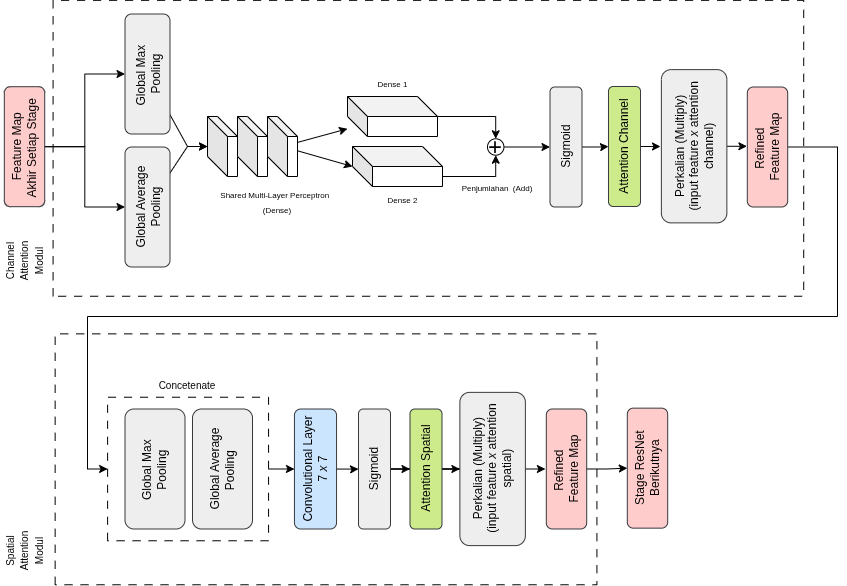

In [16]:
class ConvolutionalBlockAttentionModule(layers.Layer):
    def __init__(
        self,
        reduction_ratio=16, 
        spatial_kernel_size=7,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.reduction_ratio = reduction_ratio
        self.spatial_kernel_size = spatial_kernel_size

    # method build
    def build(self, input_shape):
        channel = input_shape[-1]
        hidden_channel = max(channel // self.reduction_ratio, 1)

        # shared MLP
        self.shared_dense_1 = Dense(hidden_channel, activation="relu", use_bias=True)

        self.shared_dense_2 = Dense(channel, use_bias=True)

        # Spatial Attention
        self.spatial_conv = Conv2D(
            filters=1,
            kernel_size=self.spatial_kernel_size,
            padding="same",
            activation="sigmoid",
            use_bias=False
        )

        super().build(input_shape)

    # method channel attention
    def channel_attention(self, x):
        # Average Pooling
        avg_pool = GlobalAveragePooling2D()(x)
        avg_pool = Reshape((1, 1, x.shape[-1]))(avg_pool)

        # Max Pooling
        max_pool = GlobalMaxPooling2D()(x)
        max_pool = Reshape((1, 1, x.shape[-1]))(max_pool)

        # Shared MLP - Average
        avg_out = self.shared_dense_1(avg_pool)
        avg_out = self.shared_dense_2(avg_out)

        # Shared MLP - Max
        max_out = self.shared_dense_1(max_pool)
        max_out = self.shared_dense_2(max_out)

        # Combine
        attention = Add()([avg_out, max_out])
        attention = Activation("sigmoid")(attention)

        # Apply Channel Attention
        x = Multiply()([x, attention])

        return x

    # method spatial attention
    def spatial_attention(self, x):
        # Average pooling across channel
        avg_pool = reduce_mean(x, axis=-1, keepdims=True)

        # Max pooling across channel
        max_pool = reduce_max(x, axis=-1, keepdims=True)

        # Concatenate
        concat = tf.concat([avg_pool, max_pool], axis=-1)

        # Spatial Attention
        attention = self.spatial_conv(concat)

        # Apply Spatial Attention
        x = Multiply()([x, attention])

        return x

    # method call channel attention and spatial attention
    def call(self, inputs):
        # Channel Attention
        x = self.channel_attention(inputs)

        # Spatial Attention
        x = self.spatial_attention(x)

        return x

    # method get config
    def get_config(self):
        config = super().get_config()
        config.update({
            "reduction_ratio": self.reduction_ratio,
            "spatial_kernel_size": self.spatial_kernel_size
        })

        return config

### 2. Membuat class ResNet50CBAM

Dalam clas ResNet50CBAM, terdapat beberapa method yang memiliki kegunaan masing-masing, diantaranya adalah:
1. **method __init__**, berguna untuk menyiapkan konfigurasi awal yang akan digunakan saat model dibangun. Terdapat beberapa parameter yang digunakan:
* a) **input_shape** ==> berguna untuk menentukan ukuran citra masukan, yaitu tinggi 224, lebar 224 dan 3 kanal RGB.
* b) **num_classes** ==> berguna untuk menentukan jumlah kelas yang akan diprediksi. Nilai 4 berarti classifier menghasilkan prediksi untuk empat kelas.
* c) **reduction_ratio** ==> berguna untuk mengatur rasio reduksi kanal pada mekanisme Channel Attention Modul CBAM.
* d) **spatial_kernel_size** ==> berguna untuk menentukan ukuran kernel konvolusi pada Spatial Attention Modul CBAM, yaitu 7 x 7.
* e) **dropout_rate** ==> berguna untuk menentukan proporsi unit yang dinonaktifkan secara acak saaat pelatihan untuk membantu mengurangi overfitting. Nilai 0.5 berarti 50%.
* Selain itu, terdapat beberapa atribut yang menjadi tempat penyimpanan objek model yang akan dibuat oleh **method build()**, diantaranya sebagai berikut:
* a) **self.backbone = None**, berguna untuk menyimpan model ResNet50 pretrained imagenet.
* b) **self.model = None**, berguna untuk menyimpan model akhir ResNet50-CBAM.
* c) **self.stem_conv2 = None**, berguna untuk menyimpan submodel dari input hingga output conv2_x
* d) **self.stage3**, **self.stage4** dan **self.stage5**, berguna untuk menyimpan submodel di setiap stagenya.
2. **method build**, berguna untuk membangun model arsitektur ResNet50-CBAM.
3. **method freeze_backbone**, berguna untuk membekukan (freeze) backbone agar bobot dari pretrained ImageNet ResNet50 tidak diperbarui selama proses pelatihan (training) model berlangsung. Dalam skenario transfer learning, model sudah memiliki pengetahuan visual dari data ImageNet. Pada tahap awal, bertujuan untuk menmpertahankan pengetahuan tersebut sambil melatih CBAM dan classifier agar menyesuaikan diri dengan citra penyakit buah kakao. Contohnya, saat model mempelajari empat kelas buah kakao, proses pelatihan model dapat diarahkan untuk mempelajari bobot CBAM dan classifier terlebih dahulu tanpa mengubah bobot konvolusi dari pretrained ImageNet.
4. **method unfreeze_top_stages**, berguna untuk membuka sebagian layer backbone agar bobotnya dapat diperbarui kembali dengan menggunakan dataset buah kakao. Disini, stage yang akan dibuka adalah **conv3_x**, **conv4_x** dan **conv5_x**. Sementara itu, **conv2_x** dan bagian awal dari ResNet50 tetap akan dibekukan (freeze). Dan juga, semua layer dari BatchNormalization juga dipertahankan dalam keadaan tidak trainable.
5. **method unfreeze_all**, berguna untuk menyediakan opsi untuk melakukan fine-tuning pada hampir seluruh backbone ResNet50, kecuali layer BatchNormalization.
6. **method _check_built**, berguna untuk memeriksa atau memastikan apakan method **build()** sudah dijalankan sebelum menjalankan method lainnya.
7. **method _print_trainable_status**, berguna untuk menampilkan informasi tentang parameter model yang dapat dan tidak dapat diperbarui selama pelatihan model berlangsung.
8. **method compile_stage_1** & **method compile_stage_2**, berguna untuk melakukan compile model ResNet50-CBAM baik untuk tahapan freeze backbone (tahap 1) maupun tahapan unfreeze conv3_x, conv4_x dan conv5_x (tahap 2). Perbedaan tahapan 1 dan tahapan2 terletak di besaran learning rate. Untuk **tahapan 1** menggunakan **learning rate sebesar 1e-4**, sedangkan untuk **tahapan 2** menggunakan **learning rate sebesar 5e-6**.

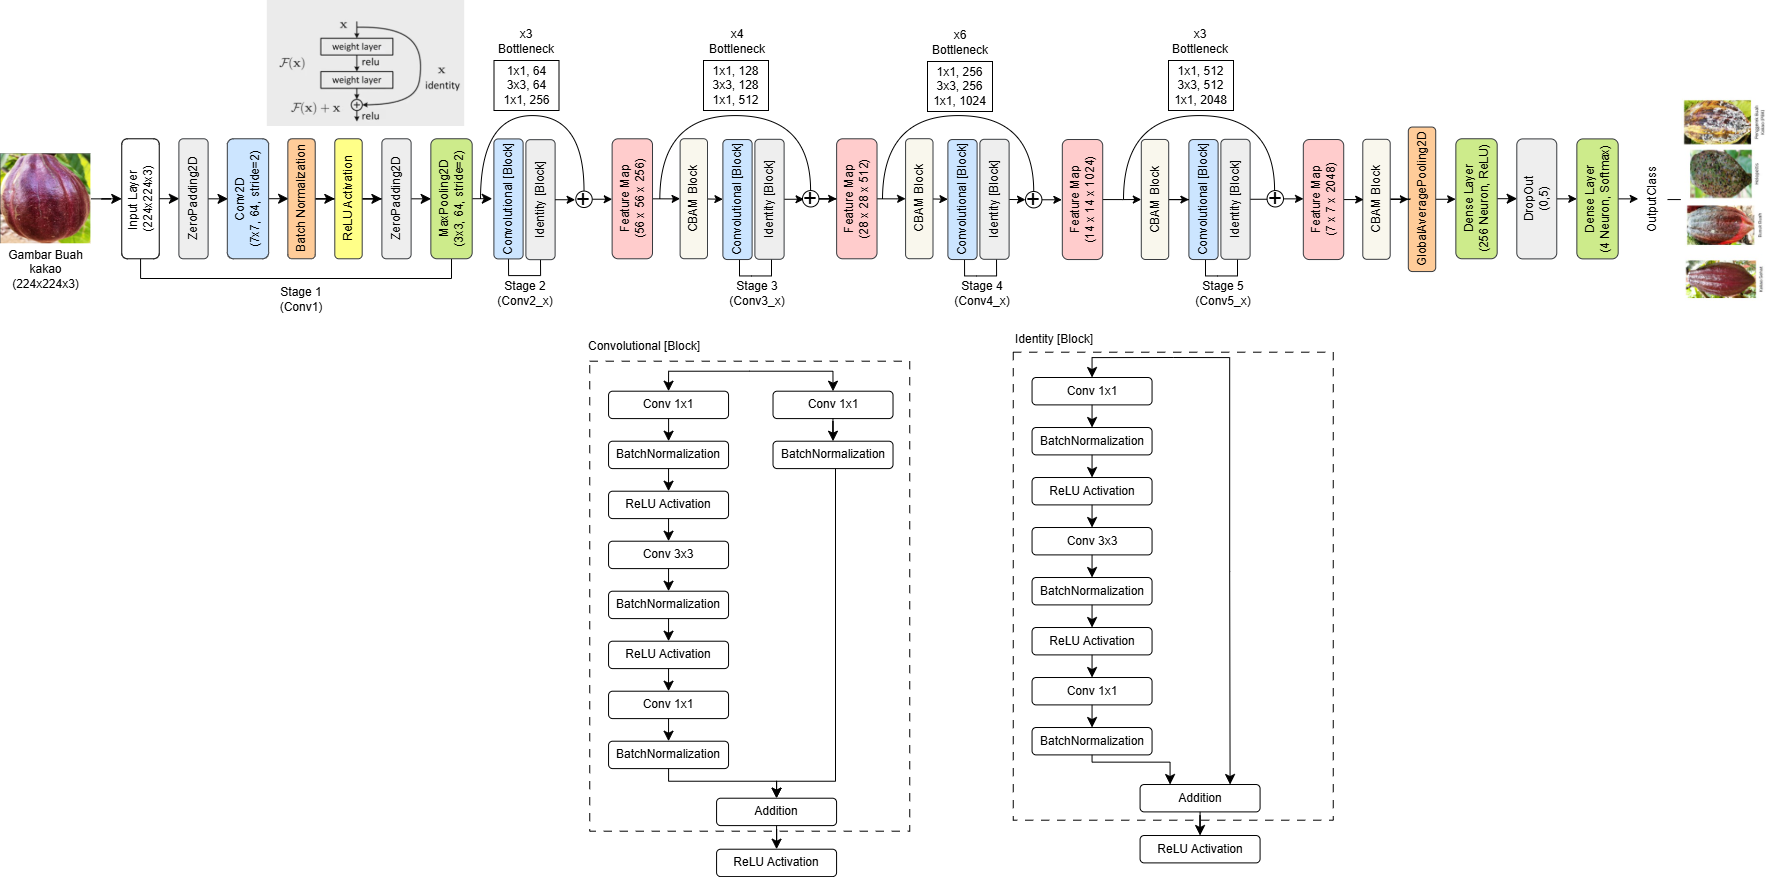

In [17]:
class ResNet50CBAM:
    def __init__(
        self,
        input_shape=(224, 224, 3),
        num_classes=4,
        reduction_ratio=16,
        spatial_kernel_size=7,
        dropout_rate=0.5
    ):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.reduction_ratio = reduction_ratio
        self.spatial_kernel_size = spatial_kernel_size
        self.dropout_rate = dropout_rate

        self.backbone = None
        self.model = None

        # submodel setiap stage ResNet50
        self.stem_conv2 = None
        self.stage3 = None
        self.stage4 = None
        self.stage5 = None

    # method build model resnet50-cbam
    def build(self):
        # =========================================================
        # 1. RESNET50 PRETRAINED IMAGENET
        # =========================================================
        self.backbone=KerasResNet50(
            include_top=False,
            weights="imagenet",
            input_shape=self.input_shape
        )

        # =========================================================
        # 2. MENGAMBIL OUTPUT SETIAP RESIDUAL STAGE
        # =========================================================
        conv2_output = self.backbone.get_layer("conv2_block3_out").output
        conv3_output = self.backbone.get_layer("conv3_block4_out").output
        conv4_output = self.backbone.get_layer("conv4_block6_out").output
        conv5_output = self.backbone.get_layer("conv5_block3_out").output

        # ===============================================================
        # 3. MEMBUAT SUBMODEL UNTUK SETIAP BAGIAN STAGE DARI RESNET50
        # ===============================================================

        # stem + stem_conv2 atau stage 2 (input = backbone ===> output = conv2_output)
        self.stem_conv2 = Model(inputs=self.backbone.input, outputs=conv2_output, name="resnet50_stem_conv2")

        # stage 3 (input = conv2_output ===> output = conv3_output)
        self.stage3 = Model(inputs=conv2_output, outputs=conv3_output, name="resnet50_conv3")

        # stage 4 (input = conv3_output ===> output = conv4_output)
        self.stage4 = Model(inputs=conv3_output, outputs=conv4_output, name="resnet50_conv4")

        # stage 5 (input = conv4_output ===> output = conv5_output)
        self.stage5 = Model(inputs=conv4_output, outputs=conv5_output, name="resnet50_conv5")

        # ===============================================================
        # 4. INPUT
        # ===============================================================
        inputs = Input(shape=self.input_shape, name="input_image")

        # ===============================================================
        # 5. STEM + CONV2_X PRETRAINED
        # ===============================================================
        x = self.stem_conv2(inputs)

        # ===============================================================
        # 6. MODUL CBAM AFTER CONV2_X
        # ===============================================================
        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv2"
        )(x)

        # ===============================================================
        # 7. CONV3_X
        # =============================================================== 
        x = self.stage3(x)

        # ===============================================================
        # 8. MODUL CBAM AFTER CONV3_X
        # ===============================================================
        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv3"
        )(x)

        # ===============================================================
        # 9. CONV4_X
        # ===============================================================
        x = self.stage4(x)

        # ===============================================================
        # 10. MODUL CBAM AFTER CONV4_x
        # ===============================================================
        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv4"
        )(x)

        # ===============================================================
        # 11. CONV5_x
        # ===============================================================
        x = self.stage5(x)

        # ===============================================================
        # 12. MODUL CBAM AFTER CONV5_X
        # ===============================================================
        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv5"
        )(x)

        # ===============================================================
        # 13. CLASSIFIER
        # ===============================================================
        x = GlobalAveragePooling2D(name="global_average_pooling")(x)
        x = Dense(256, activation="relu", name="fc1")(x)
        x = Dropout(self.dropout_rate, name="dropout")(x)
        
        outputs = Dense(
            self.num_classes,
            activation="softmax",
            name="classifier"
        )(x)

        # ===============================================================
        # 14. FINAL MODEL
        # ===============================================================
        self.model = Model(
            inputs=inputs,
            outputs=outputs,
            name="ResNet50_Pretrained_CBAM"
        )

        return self.model, self.backbone

    # method untuk membekukan (freeze) seluruh backbone pada ResNet50
    def freeze_backbone(self):
        """
        Membekukan seluruh layer backbone ResNet50.
        """
        
        self._check_built()
        self.backbone.trainable = False
        print("Backbone ResNet50 berhasil dibekukan (freeze)")
        self._print_trainable_status()

    # method untuk membuka conv3_x, conv4_x dan conv5_x, namun batch normalization tetap dibekukan (freeze)
    def unfreeze_top_stages(self):
        """
        Membuka layer Conv3_x, Conv4_x dan Conv5_x. 
        Batch Normalization tetap dibekukan (freeze).
        """

        self._check_built()

        # default seluruh backbone dibekukan (freeze)
        self.backbone.trainable=True

        for layer in self.backbone.layers:
            layer.trainable=False

            if(
                layer.name.startswith("conv3_")
                or layer.name.startswith("conv4_")
                or layer.name.startswith("conv5_")
            ):
                if not isinstance(layer, BatchNormalization):
                    layer.trainable=True

        # Tampilkan status layer
        self._print_trainable_status()

    # method untuk membuka seluruh backbone pada ResNet, selain batch normalization
    def unfreeze_all(self):
        """
        Membuka seluruh layer backbone selain Batch Normalization.
        """

        self._check_built()

        self.backbone.trainable = True

        for layer in self.backbone.layers:
            layer.trainable = not isinstance(layer, BatchNormalization)

        self._print_trainable_status()

    # method untuk check model
    def _check_built(self):
        if self.model is None or self.backbone is None:
            raise RuntimeError("Jalankan build() terlebih dahulu.")

    # method untuk print status trainable dan parameter
    def _print_trainable_status(self):
        self._check_built()

        trainable_params = sum(
            int(prod(v.shape))
            for v in self.model.trainable_weights
        )

        non_trainable_params = sum(
            int(prod(v.shape))
            for v in self.model.non_trainable_weights
        )

        print("\n=============================")
        print("STATUS BACKBONE RESNET50-CBAM")
        print("=============================")
        print("Backbone: ", self.backbone.name)
        print("Trainable backbone layers: ", 
                sum(layer.trainable for layer in self.backbone.layers)
             )
        print("Total backbone layers: ", len(self.backbone.layers))

        print("\n=============================")
        print("PARAMETER MODEL UTAMA")
        print("=============================")
        print("Trainable parameters: ", trainable_params)
        print("Non-trainable parameters: ", non_trainable_params)

        print("\nTrainable layer backbone: ")
        for layer in self.backbone.layers:
            if layer.trainable:
                print(layer.name)

    # method untuk compile model tahap 1
    def compile_stage_1(self):
        """
        Melakukan compile model untuk tahap 1:
        Backbone dibekukan, sedangkan CBAM dan classifier dilatih.
        """
        
        self._check_built()

        self.freeze_backbone()

        self.model.compile(
            optimizer=Adam(learning_rate=1e-4),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        print("Model telah berhasil di compile untuk training Tahap 1 ResNet50-CBAM")
        return self.model

    # method untuk compile model tahap 2
    def compile_stage_2(self):
        """
        Melakukan compile model untuk tahap 2:
        Fine-Tuning pada stage conv3_x, conv4_x dan conv5_x ResNet50-CBAM
        dengan Batch Normalization tetap dibekukan (freeze).
        """

        self._check_built()

        self.unfreeze_top_stages()

        self.model.compile(
            optimizer=Adam(learning_rate=5e-6),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        print("Model telah berhasil di compile untuk training Tahap 2 ResNet50-CBAM")
        return self.model

### 3. Membuat instance resnet50_cbam_builder

Instance ini diperlukan untuk menampung objek baru dengan nama resnet50_cbam_builder yang dicetak berdasarkan class ResNet50CBAM.

In [18]:
resnet50_cbam_builder = ResNet50CBAM(
    input_shape=(224, 224, 3),
    num_classes=4,
    reduction_ratio=16,
    spatial_kernel_size=7,
    dropout_rate=0.5
)

model_resnet50_cbam, resnet50_cbam_backbone = resnet50_cbam_builder.build()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [19]:
# summary model arsitektur resnet50_cbam
model_resnet50_cbam.summary()

Model: "ResNet50_Pretrained_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_stem_conv2             │ (None, 56, 56, 256)    │       229,760 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv2                      │ (None, 56, 56, 256)    │         8,562 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_conv3 (Functional)     │ (None, 28, 28, 512)    │     1,230,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv3                      │ (None, 28, 28, 512)    │        33,410 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_conv4 (Functional)     │ (None, 14, 14, 1024)   │     7,129,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv4                      │ (None, 14, 14, 1024)   │       132,258 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_conv5 (Functional)     │ (None, 7, 7, 2048)     │    14,998,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv5                      │ (None, 7, 7, 2048)     │       526,562 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,814,076 (94.66 MB)

 Trainable params: 24,760,956 (94.46 MB)

 Non-trainable params: 53,120 (207.50 KB)

### 4. Memanggil method freeze_backbone

dengan memanggil method freeze_backbone melalui instance resnet50_cbam_builder, maka code akan membekukan (freeze) seluruh layer backbone ResNet50 agar bobot pretrained tidak diperbarui selama pelatihan berlangsung, sehingga model dapat berfokus melatih bobot modul CBAM dan classifier terlebih dahulu pada tahap 1.

In [20]:
# Freeze backbone
resnet50_cbam_builder.freeze_backbone()

Backbone ResNet50 berhasil dibekukan (freeze)

STATUS BACKBONE RESNET50-CBAM
Backbone:  resnet50
Trainable backbone layers:  0
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  1226364
Non-trainable parameters:  23587712

Trainable layer backbone: 


### 5. Melakukan Compile Model (Training ResNet50-CBAM Tahap 1)

Compile Model dengan :
* Optimizer Adam
* learning rate = 1e-4
* loss = categorical crossentropy

In [21]:
resnet50_cbam_builder.compile_stage_1()

Backbone ResNet50 berhasil dibekukan (freeze)

STATUS BACKBONE RESNET50-CBAM
Backbone:  resnet50
Trainable backbone layers:  0
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  1226364
Non-trainable parameters:  23587712

Trainable layer backbone: 
Model telah berhasil di compile untuk training Tahap 1 ResNet50-CBAM


<Functional name=ResNet50_Pretrained_CBAM, built=True>

### 6. Melakukan Training Model ResNet50CBAM Tahap 1

In [22]:
history_resnet50_cbam_tahap_1 = model_resnet50_cbam.fit(
    train_dataset_resnet50,
    validation_data=val_dataset_resnet50,
    epochs=30,
    callbacks=callbacks_resnet50_cbam_tahap_1
)

Epoch 1/30
  1/175 ━━━━━━━━━━━━━━━━━━━━ 1:36:24 33s/step - accuracy: 0.1875 - loss: 1.4118

I0000 00:00:1792048064.459936     144 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - accuracy: 0.4986 - loss: 1.1284
Epoch 1: val_loss improved from None to 0.68229, saving model to best_resnet50_cbam_tahap_1.keras

Epoch 1: finished saving model to best_resnet50_cbam_tahap_1.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 127s 540ms/step - accuracy: 0.6564 - loss: 0.8440 - val_accuracy: 0.7597 - val_loss: 0.6823 - learning_rate: 1.0000e-04
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 0.8425 - loss: 0.4343
Epoch 2: val_loss improved from 0.68229 to 0.34543, saving model to best_resnet50_cbam_tahap_1.keras

Epoch 2: finished saving model to best_resnet50_cbam_tahap_1.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 72s 367ms/step - accuracy: 0.8579 - loss: 0.3965 - val_accuracy: 0.8798 - val_loss: 0.3454 - learning_rate: 1.0000e-04
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step - accuracy: 0.8743 - loss: 0.3578
Epoch 3: val_loss did not improve from 0.34543
175/175 ━━━━━━━━━━━━━━━━━━━━ 71s 361ms/step - accuracy: 0.8831 - los

### 7. Melihat Plot Akurasi dan Loss Model pada Training ResNet50CBAM Tahap 1

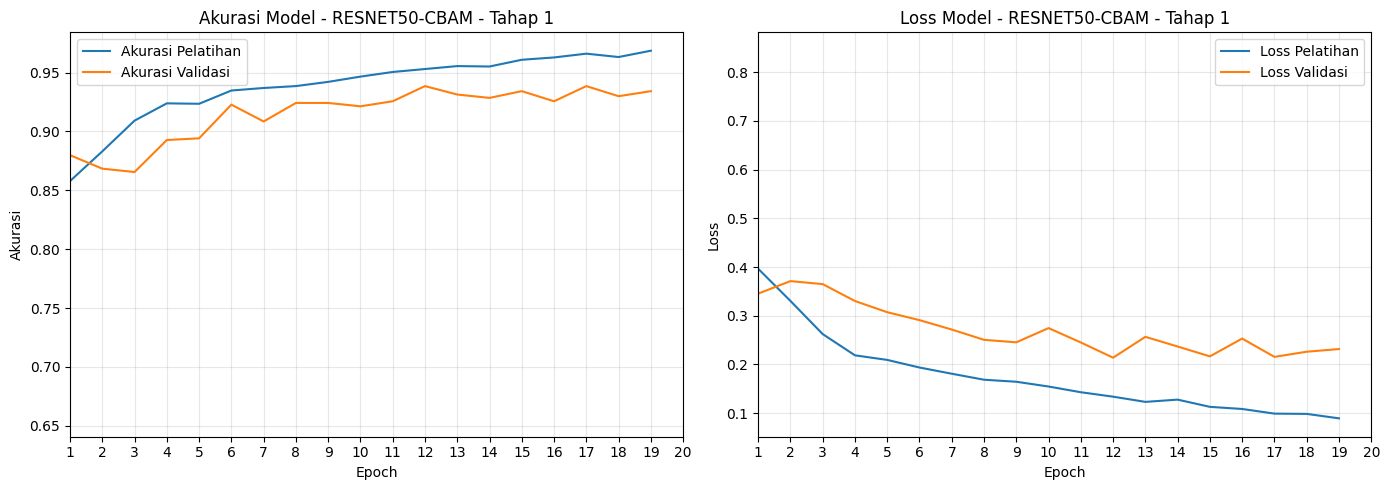

In [26]:
plot_history_training_resnet50_cbam_tahap_1 = evaluator.plot_history(
    history_resnet50_cbam_tahap_1,
    model_name="RESNET50-CBAM - Tahap 1"
)

### 8. Memanggil method unfreeze_top_stages

dengan memanggil method unfreeze_top_stages melalui instance resnet50_cbam_builder, maka code akan membuka sebagian layer backbone agar bobotnya dapat diperbarui kembali dengan menggunakan dataset buah kakao. Disini, stage yang akan dibuka adalah **conv3_x**, **conv4_x** dan **conv5_x**. Sementara itu, **conv2_x** dan bagian awal dari ResNet50 tetap akan dibekukan (freeze). Dan juga, semua layer dari BatchNormalization juga dipertahankan dalam keadaan tidak trainable.

In [27]:
# Unfreeze stage yang dipilih
resnet50_cbam_builder.unfreeze_top_stages()


STATUS BACKBONE RESNET50-CBAM
Backbone:  resnet50
Trainable backbone layers:  94
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  24483964
Non-trainable parameters:  330112

Trainable layer backbone: 
conv3_block1_1_conv
conv3_block1_1_relu
conv3_block1_2_conv
conv3_block1_2_relu
conv3_block1_0_conv
conv3_block1_3_conv
conv3_block1_add
conv3_block1_out
conv3_block2_1_conv
conv3_block2_1_relu
conv3_block2_2_conv
conv3_block2_2_relu
conv3_block2_3_conv
conv3_block2_add
conv3_block2_out
conv3_block3_1_conv
conv3_block3_1_relu
conv3_block3_2_conv
conv3_block3_2_relu
conv3_block3_3_conv
conv3_block3_add
conv3_block3_out
conv3_block4_1_conv
conv3_block4_1_relu
conv3_block4_2_conv
conv3_block4_2_relu
conv3_block4_3_conv
conv3_block4_add
conv3_block4_out
conv4_block1_1_conv
conv4_block1_1_relu
conv4_block1_2_conv
conv4_block1_2_relu
conv4_block1_0_conv
conv4_block1_3_conv
conv4_block1_add
conv4_block1_out
conv4_block2_1_conv
conv4_block2_1_relu
conv4_block2_2_conv
con

### 9. Melakukan Compile Model (Training Model ResNet50-CBAM Tahap 2)

Compile Model dengan :
* Optimizer Adam
* learning rate = 5e-6
* loss = categorical crossentropy

In [28]:
resnet50_cbam_builder.compile_stage_2()


STATUS BACKBONE RESNET50-CBAM
Backbone:  resnet50
Trainable backbone layers:  94
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  24483964
Non-trainable parameters:  330112

Trainable layer backbone: 
conv3_block1_1_conv
conv3_block1_1_relu
conv3_block1_2_conv
conv3_block1_2_relu
conv3_block1_0_conv
conv3_block1_3_conv
conv3_block1_add
conv3_block1_out
conv3_block2_1_conv
conv3_block2_1_relu
conv3_block2_2_conv
conv3_block2_2_relu
conv3_block2_3_conv
conv3_block2_add
conv3_block2_out
conv3_block3_1_conv
conv3_block3_1_relu
conv3_block3_2_conv
conv3_block3_2_relu
conv3_block3_3_conv
conv3_block3_add
conv3_block3_out
conv3_block4_1_conv
conv3_block4_1_relu
conv3_block4_2_conv
conv3_block4_2_relu
conv3_block4_3_conv
conv3_block4_add
conv3_block4_out
conv4_block1_1_conv
conv4_block1_1_relu
conv4_block1_2_conv
conv4_block1_2_relu
conv4_block1_0_conv
conv4_block1_3_conv
conv4_block1_add
conv4_block1_out
conv4_block2_1_conv
conv4_block2_1_relu
conv4_block2_2_conv
con

<Functional name=ResNet50_Pretrained_CBAM, built=True>

### 10. Melakukan Training Model ResNet50CBAM Tahap 2

In [29]:
history_resnet50_cbam_tahap_2 = model_resnet50_cbam.fit(
    train_dataset_resnet50,
    validation_data=val_dataset_resnet50,
    epochs=40,
    callbacks=callbacks_resnet50_cbam_tahap_2
)

Epoch 1/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.9501 - loss: 0.1448
Epoch 1: val_loss improved from None to 0.23198, saving model to best_resnet50_cbam_tahap_2.keras

Epoch 1: finished saving model to best_resnet50_cbam_tahap_2.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 144s 595ms/step - accuracy: 0.9499 - loss: 0.1385 - val_accuracy: 0.9371 - val_loss: 0.2320 - learning_rate: 5.0000e-06
Epoch 2/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step - accuracy: 0.9525 - loss: 0.1390
Epoch 2: val_loss improved from 0.23198 to 0.17110, saving model to best_resnet50_cbam_tahap_2.keras

Epoch 2: finished saving model to best_resnet50_cbam_tahap_2.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 86s 448ms/step - accuracy: 0.9583 - loss: 0.1214 - val_accuracy: 0.9442 - val_loss: 0.1711 - learning_rate: 5.0000e-06
Epoch 3/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step - accuracy: 0.9610 - loss: 0.1041
Epoch 3: val_loss improved from 0.17110 to 0.15107, saving model to best_resnet50_cbam_tahap_2.keras

Ep

### 11. Melihat Plot Akurasi dan Loss Model pada Training ResNet50CBAM Tahap 2

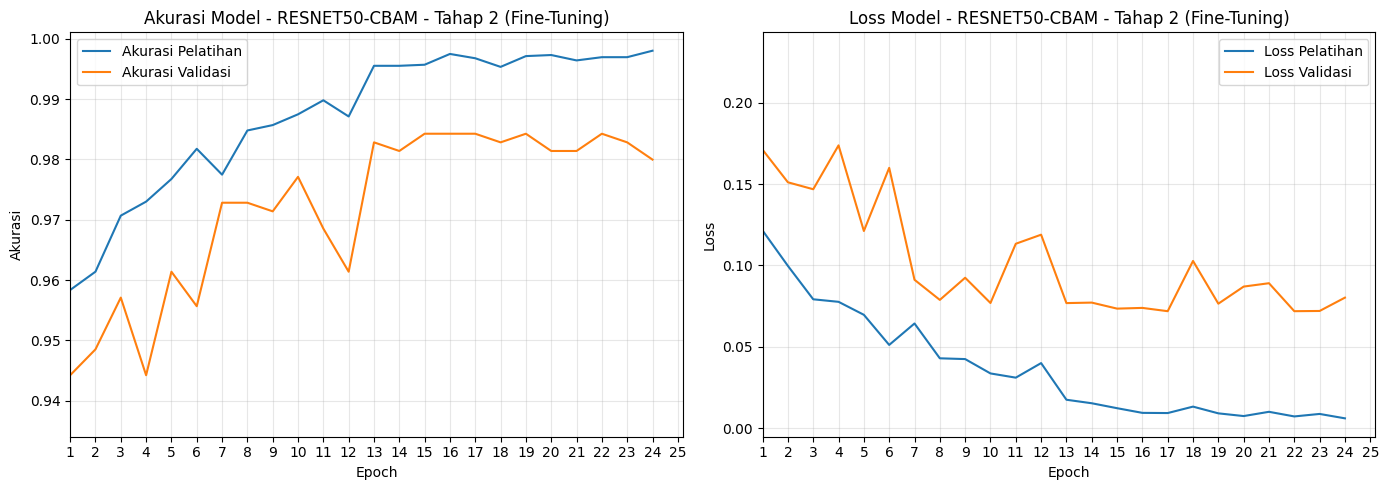

In [30]:
plot_history_training_resnet50_cbam_tahap_2 = evaluator.plot_history(
    history_resnet50_cbam_tahap_2,
    model_name="RESNET50-CBAM - Tahap 2 (Fine-Tuning)"
)

## C. Model Arsitektur ResNet50

Saat melakukan pelatihan pada model arsitektur ResNet50, terdapat beberapa tahapan yang perlu dilakukan, diantaranya adalah:
1. Membuat class ResNet50
2. Membuat instance resnet50_builder
3. Memanggil method freeze_backbone
4. Melakukan Compile Model (Training ResNet50 Tahap 1)
5. Melakukan Training Model ResNet50 Tahap 1
6. Melihat Plot Akurasi dan Loss Model pada Training ResNet50 Tahap 1
7. Memanggil method unfreeze_top_stages
8. Melakukan Compile Model (Training Model ResNet50 Tahap 2)
9. Melakukan Training Model ResNet50 Tahap 2
10. Melihat Plot Akurasi dan Loss Model pada Training ResNet50 Tahap 2

### 1. Membuat class ResNet50

Dalam clas ResNet50, terdapat beberapa method yang memiliki kegunaan masing-masing, diantaranya adalah:
1. **method __init__**, berguna untuk menyiapkan konfigurasi awal yang akan digunakan saat model dibangun. Terdapat beberapa parameter yang digunakan:
* a) **input_shape** ==> berguna untuk menentukan ukuran citra masukan, yaitu tinggi 224, lebar 224 dan 3 kanal RGB.
* b) **num_classes** ==> berguna untuk menentukan jumlah kelas yang akan diprediksi. Nilai 4 berarti classifier menghasilkan prediksi untuk empat kelas.
* c) **dropout_rate** ==> berguna untuk menentukan proporsi unit yang dinonaktifkan secara acak saaat pelatihan untuk membantu mengurangi overfitting. Nilai 0.5 berarti 50%.
* Selain itu, terdapat beberapa atribut yang menjadi tempat penyimpanan objek model yang akan dibuat oleh **method build()**, diantaranya sebagai berikut:
* a) **self.backbone = None**, berguna untuk menyimpan model ResNet50 pretrained imagenet.
* b) **self.model = None**, berguna untuk menyimpan model akhir ResNet50.
2. **method build**, berguna untuk membangun model arsitektur ResNet50.
3. **method freeze_backbone**, berguna untuk membekukan (freeze) backbone agar bobot dari pretrained ImageNet ResNet50 tidak diperbarui selama proses pelatihan (training) model berlangsung. Dalam skenario transfer learning, model sudah memiliki pengetahuan visual dari data ImageNet. Pada tahap awal, bertujuan untuk menmpertahankan pengetahuan tersebut sambil melatih CBAM dan classifier agar menyesuaikan diri dengan citra penyakit buah kakao. Contohnya, saat model mempelajari empat kelas buah kakao, proses pelatihan model dapat diarahkan untuk mempelajari bobot CBAM dan classifier terlebih dahulu tanpa mengubah bobot konvolusi dari pretrained ImageNet.
4. **method unfreeze_top_stages**, berguna untuk membuka sebagian layer backbone agar bobotnya dapat diperbarui kembali dengan menggunakan dataset buah kakao. Disini, stage yang akan dibuka adalah **conv3_x**, **conv4_x** dan **conv5_x**. Sementara itu, **conv2_x** dan bagian awal dari ResNet50 tetap akan dibekukan (freeze). Dan juga, semua layer dari BatchNormalization juga dipertahankan dalam keadaan tidak trainable.
5. **method unfreeze_all**, berguna untuk menyediakan opsi untuk melakukan fine-tuning pada hampir seluruh backbone ResNet50, kecuali layer BatchNormalization.
6. **method _check_built**, berguna untuk memeriksa atau memastikan apakan method **build()** sudah dijalankan sebelum menjalankan method lainnya.
7. **method _print_trainable_status**, berguna untuk menampilkan informasi tentang parameter model yang dapat dan tidak dapat diperbarui selama pelatihan model berlangsung.
8. **method compile_stage_1** & **method compile_stage_2**, berguna untuk melakukan compile model ResNet50-CBAM baik untuk tahapan freeze backbone (tahap 1) maupun tahapan unfreeze conv3_x, conv4_x dan conv5_x (tahap 2). Perbedaan tahapan 1 dan tahapan2 terletak di besaran learning rate. Untuk **tahapan 1** menggunakan **learning rate sebesar 1e-4**, sedangkan untuk **tahapan 2** menggunakan **learning rate sebesar 5e-6**.

In [31]:
class ResNet50:
    def __init__(
        self,
        input_shape=(224, 224, 3),
        num_classes=4,
        dropout_rate=0.5
    ):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.dropout_rate = dropout_rate

        self.backbone = None
        self.model = None

    # method build model resnet50 baseline
    def build(self):
        """Membangun model ResNet50 baseline."""
        # ===================================
        # 1. RESNET50 PRETRAINED IMAGENET
        # ===================================
        self.backbone = KerasResNet50(
            include_top=False,
            weights="imagenet",
            input_shape=self.input_shape
        )

        # ===================================
        # 2. INPUT
        # ===================================
        inputs = Input(
            shape=self.input_shape,
            name="input_image"
        )

        # ===================================
        # 3. FEATURE EXTRACTION
        # ===================================
        x = self.backbone(inputs, training=False)

        # ===================================
        # 4. CLASSIFIER
        # ===================================
        x = GlobalAveragePooling2D(name="global_average_pooling")(x)
        x = Dense(
            256, 
            activation="relu", 
            name="fc1"
        )(x)
        x = Dropout(
            self.dropout_rate, 
            name="dropoout"
        )(x)
        outputs = Dense(
            self.num_classes, 
            activation="softmax",
            name="classifier"
        )(x)

        # ===================================
        # 5. FINAL MODEL
        # ===================================
        self.model = Model(
            inputs=inputs,
            outputs=outputs,
            name="ResNet50_Baseline"
        )

        return self.model, self.backbone
    
    # method untuk membekukan seluruh backbone pada ResNet
    def freeze_backbone(self):
        """Membekukan seluruh backbone."""
        self._check_built()

        self.backbone.trainable = False
        self._print_trainable_status()

    # method untuk membuka conv3_x, conv4_x dan con5_x, namun batch normalization tetap dibekukan (freeze)
    def unfreeze_top_stages(self):
        """
        Membuka Conv3_x, Conv4_x, dan Conv5_x.
        Batch Normalization tetap dibekukan.
        """
        self._check_built()

        self.backbone.trainable = True

        for layer in self.backbone.layers:
            layer.trainable = False

            if(
                layer.name.startswith("conv3_")
                or layer.name.startswith("conv4_")
                or layer.name.startswith("conv5_")
            ):
                if not isinstance(layer, BatchNormalization):
                    layer.trainable = True
        
        self._print_trainable_status()

    # method untuk membuka seluruh backbone pada ResNet, selain batch normalization
    def unfreeze_all(self):
        """Membuka seluruh layer backbone pada ResNet, selain batch normalization."""
        self._check_built()

        self.backbone.trainable = True

        for layer in self.backbone.layers:
            layer.trainable = not isinstance(layer, BacthNormalization)

        self._print_trainable_status()

    # method untuk check model
    def _check_built(self):
        if self.model is None or self.backbone is None:
            raise RuntimeError("Jalankan build() terlebih dahulu.")

    # method untuk print status trainable dan parameter
    def _print_trainable_status(self):
        self._check_built()

        trainable_params = sum(
            int(prod(v.shape))
            for v in self.model.trainable_weights
        )

        non_trainable_params = sum(
            int(prod(v.shape))
            for v in self.model.non_trainable_weights
        )

        print("\n=============================")
        print("STATUS BACKBONE RESNET50")
        print("=============================")
        print("Backbone: ", self.backbone.name)
        print("Trainable backbone layers: ", 
                sum(layer.trainable for layer in self.backbone.layers)
             )
        print("Total backbone layers: ", len(self.backbone.layers))

        print("\n=============================")
        print("PARAMETER MODEL UTAMA")
        print("=============================")
        print("Trainable parameters: ", trainable_params)
        print("Non-trainable parameters: ", non_trainable_params)

        print("\nTrainable layer backbone: ")
        for layer in self.backbone.layers:
            if layer.trainable:
                print(layer.name)
    
    # method untuk compile model tahap 1
    def compile_stage_1(self):
        """
        Melakukan compile model untuk tahap 1:
        Backbone dibekukan, sedangkan classifier dilatih.
        """
        
        self._check_built()

        self.freeze_backbone()

        self.model.compile(
            optimizer=Adam(learning_rate=1e-4),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        print("Model telah berhasil di compile untuk training Tahap 1 ResNet50.")
        return self.model

    # method untuk compile model tahap 2
    def compile_stage_2(self):
        """
        Melakukan compile model untuk tahap 2:
        Fine-Tuning pada stage conv3_x, conv4_x dan conv5_x ResNet50 
        dengan Batch Normalization tetap dibekukan (freeze).
        """

        self._check_built()

        self.unfreeze_top_stages()

        self.model.compile(
            optimizer=Adam(learning_rate=5e-6),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        print("Model telah berhasil di compile untuk training Tahap 2 ResNet50.")
        return self.model

### 2. Membuat instance resnet50_builder

In [32]:
resnet50_builder = ResNet50(
    input_shape=(224, 224, 3),
    num_classes=4,
    dropout_rate=0.5
)

model_resnet50, resnet50_backbone = resnet50_builder.build()

In [33]:
# summary model arsitektur resnet50
model_resnet50.summary()

Model: "ResNet50_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropoout (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 24,060,164 (91.78 MB)

 Non-trainable params: 53,120 (207.50 KB)

### 3. Memanggil method freeze_backbone

In [34]:
# Freeze backbone
resnet50_builder.freeze_backbone()


STATUS BACKBONE RESNET50
Backbone:  resnet50
Trainable backbone layers:  0
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  525572
Non-trainable parameters:  23587712

Trainable layer backbone: 


### 4. Melakukan Compile Model (Training ResNet50 Tahap 1)

In [35]:
resnet50_builder.compile_stage_1()


STATUS BACKBONE RESNET50
Backbone:  resnet50
Trainable backbone layers:  0
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  525572
Non-trainable parameters:  23587712

Trainable layer backbone: 
Model telah berhasil di compile untuk training Tahap 1 ResNet50.


<Functional name=ResNet50_Baseline, built=True>

### 5. Melakukan Training Model ResNet50 Tahap 1

In [36]:
history_resnet50_tahap_1 = model_resnet50.fit(
    train_dataset_resnet50,
    validation_data=val_dataset_resnet50,
    epochs=30,
    callbacks=callbacks_resnet50_tahap_1
)

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.5897 - loss: 1.0490
Epoch 1: val_loss improved from None to 0.30528, saving model to best_resnet50_tahap_1.keras

Epoch 1: finished saving model to best_resnet50_tahap_1.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 82s 360ms/step - accuracy: 0.7456 - loss: 0.6762 - val_accuracy: 0.8970 - val_loss: 0.3053 - learning_rate: 1.0000e-04
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.8879 - loss: 0.3372
Epoch 2: val_loss improved from 0.30528 to 0.23274, saving model to best_resnet50_tahap_1.keras

Epoch 2: finished saving model to best_resnet50_tahap_1.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 61s 302ms/step - accuracy: 0.8915 - loss: 0.3172 - val_accuracy: 0.9256 - val_loss: 0.2327 - learning_rate: 1.0000e-04
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.9214 - loss: 0.2608
Epoch 3: val_loss improved from 0.23274 to 0.17794, saving model to best_resnet50_tahap_1.keras

Epoch 3: finished saving mod

### 6. Melihat Plot Akurasi dan Loss Model pada Training ResNet50 Tahap 1

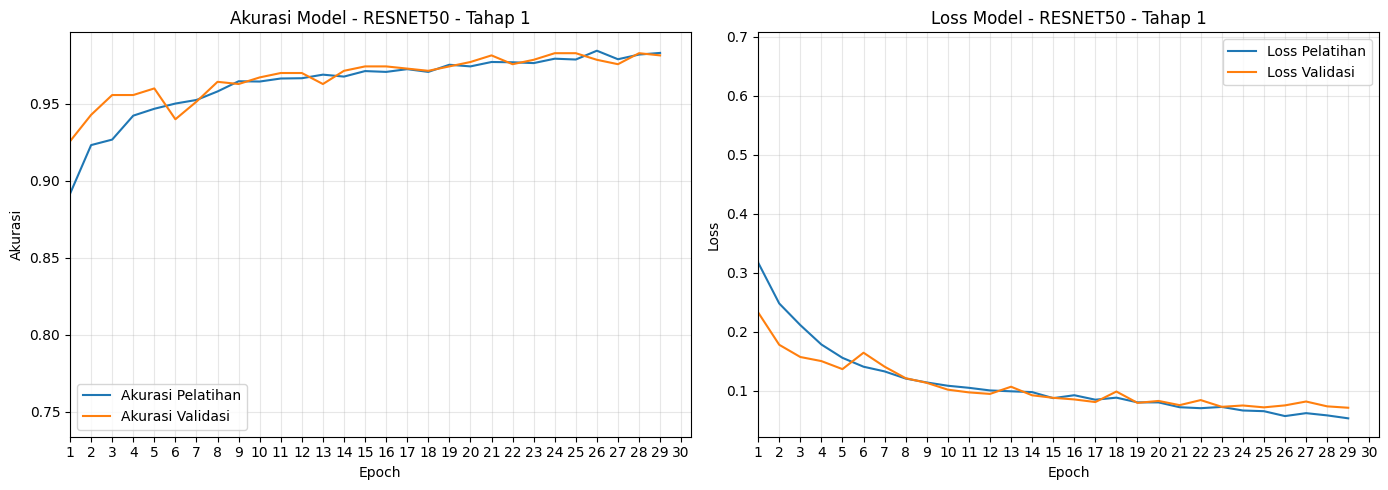

In [37]:
plot_history_training_resnet50_tahap_1 = evaluator.plot_history(
    history_resnet50_tahap_1,
    model_name="RESNET50 - Tahap 1"
)

### 7. Memanggil method unfreeze_top_stages

In [38]:
# Unfreeze stage yang dipilih
resnet50_builder.unfreeze_top_stages()


STATUS BACKBONE RESNET50
Backbone:  resnet50
Trainable backbone layers:  94
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  23783172
Non-trainable parameters:  330112

Trainable layer backbone: 
conv3_block1_1_conv
conv3_block1_1_relu
conv3_block1_2_conv
conv3_block1_2_relu
conv3_block1_0_conv
conv3_block1_3_conv
conv3_block1_add
conv3_block1_out
conv3_block2_1_conv
conv3_block2_1_relu
conv3_block2_2_conv
conv3_block2_2_relu
conv3_block2_3_conv
conv3_block2_add
conv3_block2_out
conv3_block3_1_conv
conv3_block3_1_relu
conv3_block3_2_conv
conv3_block3_2_relu
conv3_block3_3_conv
conv3_block3_add
conv3_block3_out
conv3_block4_1_conv
conv3_block4_1_relu
conv3_block4_2_conv
conv3_block4_2_relu
conv3_block4_3_conv
conv3_block4_add
conv3_block4_out
conv4_block1_1_conv
conv4_block1_1_relu
conv4_block1_2_conv
conv4_block1_2_relu
conv4_block1_0_conv
conv4_block1_3_conv
conv4_block1_add
conv4_block1_out
conv4_block2_1_conv
conv4_block2_1_relu
conv4_block2_2_conv
conv4_bl

### 8. Melakukan Compile Model (Training Model ResNet50 Tahap 2)

In [39]:
resnet50_builder.compile_stage_2()


STATUS BACKBONE RESNET50
Backbone:  resnet50
Trainable backbone layers:  94
Total backbone layers:  175

PARAMETER MODEL UTAMA
Trainable parameters:  23783172
Non-trainable parameters:  330112

Trainable layer backbone: 
conv3_block1_1_conv
conv3_block1_1_relu
conv3_block1_2_conv
conv3_block1_2_relu
conv3_block1_0_conv
conv3_block1_3_conv
conv3_block1_add
conv3_block1_out
conv3_block2_1_conv
conv3_block2_1_relu
conv3_block2_2_conv
conv3_block2_2_relu
conv3_block2_3_conv
conv3_block2_add
conv3_block2_out
conv3_block3_1_conv
conv3_block3_1_relu
conv3_block3_2_conv
conv3_block3_2_relu
conv3_block3_3_conv
conv3_block3_add
conv3_block3_out
conv3_block4_1_conv
conv3_block4_1_relu
conv3_block4_2_conv
conv3_block4_2_relu
conv3_block4_3_conv
conv3_block4_add
conv3_block4_out
conv4_block1_1_conv
conv4_block1_1_relu
conv4_block1_2_conv
conv4_block1_2_relu
conv4_block1_0_conv
conv4_block1_3_conv
conv4_block1_add
conv4_block1_out
conv4_block2_1_conv
conv4_block2_1_relu
conv4_block2_2_conv
conv4_bl

<Functional name=ResNet50_Baseline, built=True>

### 9. Melakukan Training Model ResNet50 Tahap 2

In [40]:
history_resnet50_tahap_2 = model_resnet50.fit(
    train_dataset_resnet50,
    validation_data=val_dataset_resnet50,
    epochs=40,
    callbacks=callbacks_resnet50_tahap_2
)

Epoch 1/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.9740 - loss: 0.0675
Epoch 1: val_loss improved from None to 0.05180, saving model to best_resnet50_tahap_2.keras

Epoch 1: finished saving model to best_resnet50_tahap_2.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 121s 520ms/step - accuracy: 0.9777 - loss: 0.0599 - val_accuracy: 0.9843 - val_loss: 0.0518 - learning_rate: 5.0000e-06
Epoch 2/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step - accuracy: 0.9832 - loss: 0.0556
Epoch 2: val_loss did not improve from 0.05180
175/175 ━━━━━━━━━━━━━━━━━━━━ 82s 424ms/step - accuracy: 0.9859 - loss: 0.0460 - val_accuracy: 0.9828 - val_loss: 0.0545 - learning_rate: 5.0000e-06
Epoch 3/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.9899 - loss: 0.0296
Epoch 3: val_loss did not improve from 0.05180

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
175/175 ━━━━━━━━━━━━━━━━━━━━ 81s 419ms/step - accuracy: 0.9902 - loss: 0.0301 - val_accuracy: 0.9757 - val_loss:

### 10. Melihat Plot Akurasi dan Loss Model pada Training ResNet50 Tahap 2

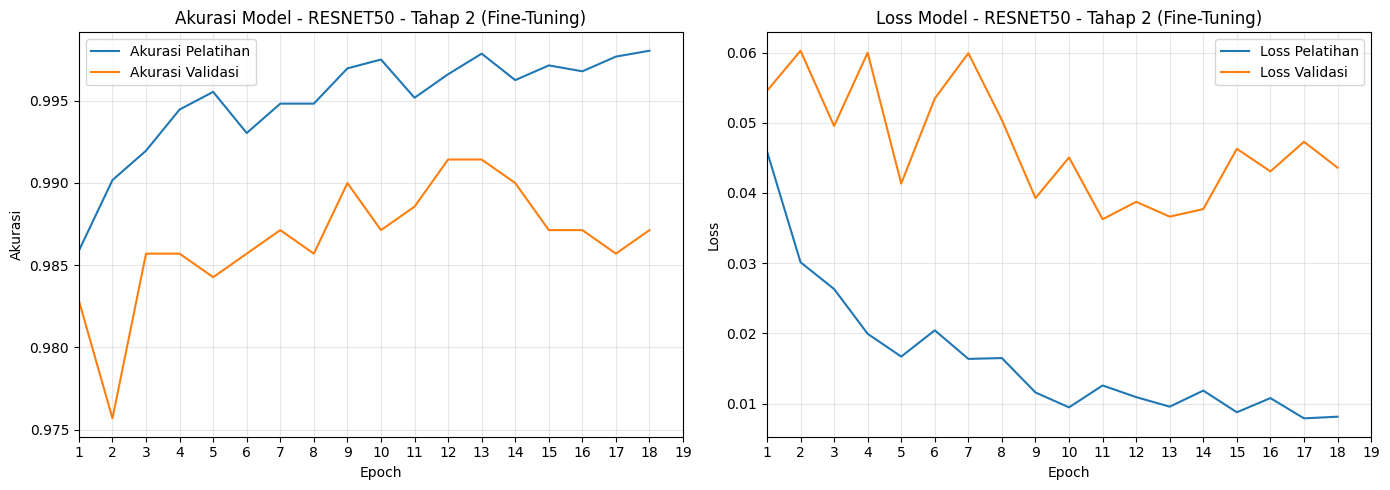

In [41]:
plot_history_training_resnet50_tahap_2 = evaluator.plot_history(
    history_resnet50_tahap_2,
    model_name="RESNET50 - Tahap 2 (Fine-Tuning)"
)

## D. Model ResNet152V2

Saat melakukan pelatihan pada model arsitektur ResNet152V2, terdapat beberapa tahapan yang perlu dilakukan, diantaranya adalah:
1. Membuat class ResNet152V2
2. Membuat instance resnet152v2_builder
3. Memanggil method freeze_backbone
4. Melakukan Compile Model (Training ResNet152v2 Tahap 1)
5. Melakukan Training Model ResNet152v2 Tahap 1
6. Melihat Plot Akurasi dan Loss Model pada Training ResNet152v2 Tahap 1
7. Memanggil method unfreeze_top_stages
8. Melakukan Compile Model (Training Model ResNet152v2 Tahap 2)
9. Melakukan Training Model ResNet152v2 Tahap 2
10. Melihat Plot Akurasi dan Loss Model pada Training ResNet152v2 Tahap 2

### 1. Membuat class ResNet152V2

Dalam clas ResNet152V2, terdapat beberapa method yang memiliki kegunaan masing-masing, diantaranya adalah:
1. **method __init__**, berguna untuk menyiapkan konfigurasi awal yang akan digunakan saat model dibangun. Terdapat beberapa parameter yang digunakan:
* a) **input_shape** ==> berguna untuk menentukan ukuran citra masukan, yaitu tinggi 224, lebar 224 dan 3 kanal RGB.
* b) **num_classes** ==> berguna untuk menentukan jumlah kelas yang akan diprediksi. Nilai 4 berarti classifier menghasilkan prediksi untuk empat kelas.
* c) **dropout_rate** ==> berguna untuk menentukan proporsi unit yang dinonaktifkan secara acak saaat pelatihan untuk membantu mengurangi overfitting. Nilai 0.5 berarti 50%.
* Selain itu, terdapat beberapa atribut yang menjadi tempat penyimpanan objek model yang akan dibuat oleh **method build()**, diantaranya sebagai berikut:
* a) **self.backbone = None**, berguna untuk menyimpan model ResNet50 pretrained imagenet.
* b) **self.model = None**, berguna untuk menyimpan model akhir ResNet50.
2. **method build**, berguna untuk membangun model arsitektur ResNet50.
3. **method freeze_backbone**, berguna untuk membekukan (freeze) backbone agar bobot dari pretrained ImageNet ResNet50 tidak diperbarui selama proses pelatihan (training) model berlangsung. Dalam skenario transfer learning, model sudah memiliki pengetahuan visual dari data ImageNet. Pada tahap awal, bertujuan untuk menmpertahankan pengetahuan tersebut sambil melatih CBAM dan classifier agar menyesuaikan diri dengan citra penyakit buah kakao. Contohnya, saat model mempelajari empat kelas buah kakao, proses pelatihan model dapat diarahkan untuk mempelajari bobot CBAM dan classifier terlebih dahulu tanpa mengubah bobot konvolusi dari pretrained ImageNet.
4. **method unfreeze_top_stages**, berguna untuk membuka sebagian layer backbone agar bobotnya dapat diperbarui kembali dengan menggunakan dataset buah kakao. Disini, stage yang akan dibuka adalah **conv3_x**, **conv4_x** dan **conv5_x**. Sementara itu, **conv2_x** dan bagian awal dari ResNet50 tetap akan dibekukan (freeze). Dan juga, semua layer dari BatchNormalization juga dipertahankan dalam keadaan tidak trainable.
5. **method unfreeze_all**, berguna untuk menyediakan opsi untuk melakukan fine-tuning pada hampir seluruh backbone ResNet50, kecuali layer BatchNormalization.
6. **method _check_built**, berguna untuk memeriksa atau memastikan apakan method **build()** sudah dijalankan sebelum menjalankan method lainnya.
7. **method _print_trainable_status**, berguna untuk menampilkan informasi tentang parameter model yang dapat dan tidak dapat diperbarui selama pelatihan model berlangsung.
8. **method compile_stage_1** & **method compile_stage_2**, berguna untuk melakukan compile model ResNet50-CBAM baik untuk tahapan freeze backbone (tahap 1) maupun tahapan unfreeze conv3_x, conv4_x dan conv5_x (tahap 2). Perbedaan tahapan 1 dan tahapan2 terletak di besaran learning rate. Untuk **tahapan 1** menggunakan **learning rate sebesar 1e-4**, sedangkan untuk **tahapan 2** menggunakan **learning rate sebesar 5e-6**.

In [50]:
class ResNet152V2:
    def __init__(
        self,
        input_shape=(224, 224, 3),
        num_classes=4,
        dropout_rate=0.5
    ):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.dropout_rate = dropout_rate

        self.backbone = None
        self.model = None

    # method build model ResNet152V2
    def build(self):
        # ===================================
        # 1. RESNET152V2 PRETRAINED IMAGENET
        # ===================================
        self.backbone = KerasResNet152V2(
            include_top=False,
            weights="imagenet",
            input_shape=self.input_shape
        )

        # ===================================
        # 2. INPUT
        # ===================================
        inputs = Input(
            shape=self.input_shape,
            name="input_image"
        )

        # ===================================
        # 3. FEATURE EXTRACTION
        # ===================================
        x = self.backbone(inputs)

        # ===================================
        # 4. CLASSIFIER
        # ===================================
        x = GlobalAveragePooling2D(name="global_average_pooling")(x)
        x = Dense(
            256,
            activation="relu",
            name="fc1"
        )(x)
        x = layers.Dropout(
            self.dropout_rate,
            name="dropout"
        )(x)
        outputs = Dense(
            self.num_classes,
            activation="softmax",
            name="classifier"
        )(x)

        # ===================================
        # 5. FINAL MODEL
        # ===================================
        self.model = Model(
            inputs=inputs,
            outputs=outputs,
            name="ResNet152V2"
        )

        return self.model, self.backbone

    # method untuk membekukan seluruh backbone pada ResNet
    def freeze_backbone(self):
        """Membekukan seluruh backbone."""
        self._check_built()

        self.backbone.trainable = False
        self._print_trainable_status()

    # method untuk membuka conv3_x, conv4_x dan conv5_x, namun batch normalization tetap dibekukan
    def unfreeze_top_stages(self):
        """Membuka stage conv3_x, conv4_x dan conv5_x berdasarkan prefix nama layer. 
        namun, batch normalization tetap dibekukan.
        """
        self._check_built()

        self.backbone.trainable = True

        for layer in self.backbone.layers:
            layer.trainable = False

            if(
                layer.name.startswith("conv3_")
                or layer.name.startswith("conv4_")
                or layer.name.startswith("conv5_")
            ):
                if not isinstance(layer, BatchNormalization):
                    layer.trainable = True

        self._print_trainable_status()

    # method untuk membuka seluruh layer selain batch normalization
    def unfreeze_all(self):
        """Membuka seluruh layer selain batch normalization."""
        self._check_built()

        self.backbone.trainable = True

        for layer in self.backbone.layers:
            layer.trainable = not isinstance(layer, BatchNormalization)

        self._print_trainable_status()

    # method untuk check model
    def _check_built(self):
        if self.model is None or self.backbone is None:
            raise RuntimeError("Jalankan build() terlebih dahulu.")

    # method untuk print status trainable dan parameter
    def _print_trainable_status(self):
        self._check_built()

        trainable_params = sum(
            int(prod(v.shape))
            for v in self.model.trainable_weights
        )

        non_trainable_params = sum(
            int(prod(v.shape))
            for v in self.model.non_trainable_weights
        )

        print("\n=============================")
        print("STATUS BACKBONE RESNET50")
        print("=============================")
        print("Backbone: ", self.backbone.name)
        print("Trainable backbone layers: ", 
                sum(layer.trainable for layer in self.backbone.layers)
             )
        print("Total backbone layers: ", len(self.backbone.layers))

        print("\n=============================")
        print("PARAMETER MODEL UTAMA")
        print("=============================")
        print("Trainable parameters: ", trainable_params)
        print("Non-trainable parameters: ", non_trainable_params)

        print("\nTrainable layer backbone: ")
        for layer in self.backbone.layers:
            if layer.trainable:
                print(layer.name)

    # method untuk compile model tahap 1
    def compile_stage_1(self):
        """
        Melakukan compile model untuk tahap 1:
        Backbone dibekukan, sedangkan classifier dilatih.
        """
        
        self._check_built()

        self.freeze_backbone()

        self.model.compile(
            optimizer=Adam(learning_rate=1e-4),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        print("Model telah berhasil di compile untuk training Tahap 1 ResNet152V2.")
        return self.model

    # method untuk compile model tahap 2
    def compile_stage_2(self):
        """
        Melakukan compile model untuk tahap 2:
        Fine-Tuning pada stage conv3_x, conv4_x dan conv5_x ResNet152V2
        dengan Batch Normalization tetap dibekukan (freeze).
        """

        self._check_built()

        self.unfreeze_top_stages()

        self.model.compile(
            optimizer=Adam(learning_rate=5e-6),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        print("Model telah berhasil di compile untuk training Tahap 2 ResNet152V2.")
        return self.model

### 2. Membuat instance resnet152v2_builder

In [51]:
resnet152v2_builder = ResNet152V2(
    input_shape=(224, 224, 3),
    num_classes=4,
    dropout_rate=0.5
)

model_resnet152v2, resnet152v2_backbone = resnet152v2_builder.build()

In [52]:
# summary model arsitektur resnet152V2
model_resnet152v2.summary()

Model: "ResNet152V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet152v2 (Functional)        │ (None, 7, 7, 2048)     │    58,331,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,857,220 (224.52 MB)

 Trainable params: 58,713,476 (223.97 MB)

 Non-trainable params: 143,744 (561.50 KB)

### 3. Memanggil method freeze_backbone

In [45]:
# Freeze backbone
resnet152v2_builder.freeze_backbone()


STATUS BACKBONE RESNET50
Backbone:  resnet152v2
Trainable backbone layers:  0
Total backbone layers:  564

PARAMETER MODEL UTAMA
Trainable parameters:  525572
Non-trainable parameters:  58331648

Trainable layer backbone: 


### 4. Melakukan Compile Model (Training ResNet152v2 Tahap 1)

In [46]:
resnet152v2_builder.compile_stage_1()


STATUS BACKBONE RESNET50
Backbone:  resnet152v2
Trainable backbone layers:  0
Total backbone layers:  564

PARAMETER MODEL UTAMA
Trainable parameters:  525572
Non-trainable parameters:  58331648

Trainable layer backbone: 
Model telah berhasil di compile untuk training Tahap 1 ResNet152V2.


<Functional name=ResNet152V2, built=True>

### 5. Melakukan Training Model ResNet152v2 Tahap 1

In [47]:
history_resnet152v2_tahap_1 = model_resnet152v2.fit(
    train_dataset_resnet152v2,
    validation_data=val_dataset_resnet152v2,
    epochs=30,
    callbacks=callbacks_resnet152v2_tahap_1
)

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - accuracy: 0.5256 - loss: 1.1870
Epoch 1: val_loss improved from None to 0.39021, saving model to best_resnet152v2_tahap_1.keras

Epoch 1: finished saving model to best_resnet152v2_tahap_1.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 127s 547ms/step - accuracy: 0.6590 - loss: 0.8596 - val_accuracy: 0.8712 - val_loss: 0.3902 - learning_rate: 1.0000e-04
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.8158 - loss: 0.5145
Epoch 2: val_loss improved from 0.39021 to 0.32074, saving model to best_resnet152v2_tahap_1.keras

Epoch 2: finished saving model to best_resnet152v2_tahap_1.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 80s 414ms/step - accuracy: 0.8259 - loss: 0.4782 - val_accuracy: 0.8841 - val_loss: 0.3207 - learning_rate: 1.0000e-04
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.8585 - loss: 0.3879
Epoch 3: val_loss improved from 0.32074 to 0.27514, saving model to best_resnet152v2_tahap_1.keras

Epoch 3: fin

### 6. Melihat Plot Akurasi dan Loss Model pada Training ResNet152v2 Tahap 1

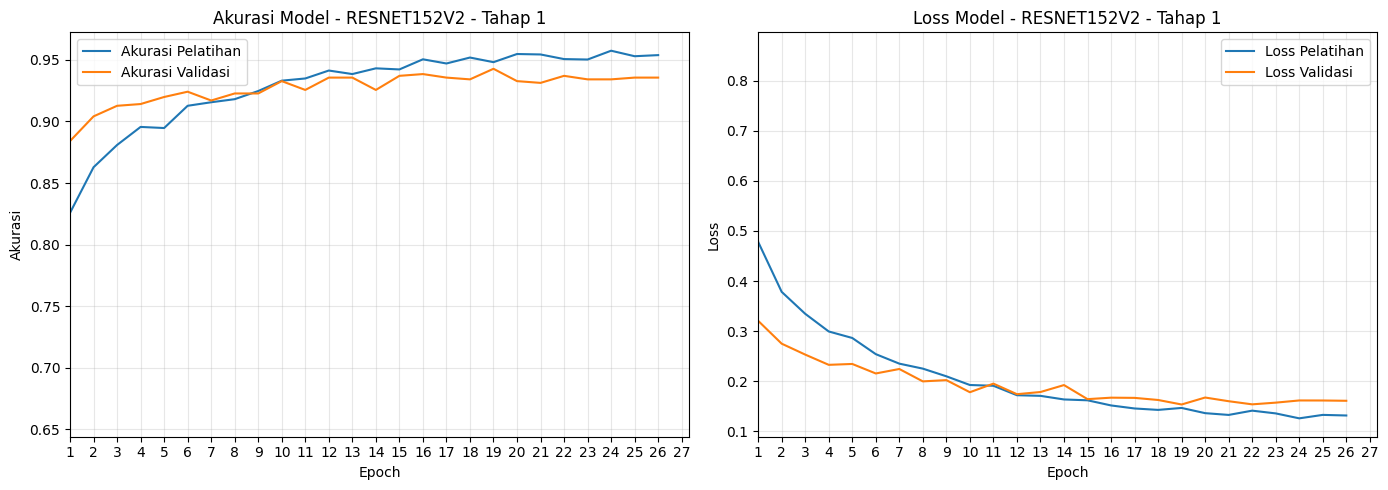

In [48]:
plot_history_training_resnet152v2_tahap_1 = evaluator.plot_history(
    history_resnet152v2_tahap_1,
    model_name="RESNET152V2 - Tahap 1"
)

### 7. Memanggil method unfreeze_top_stages

In [53]:
# Unfreeze stage yang dipilih
resnet152v2_builder.unfreeze_top_stages()


STATUS BACKBONE RESNET50
Backbone:  resnet152v2
Trainable backbone layers:  379
Total backbone layers:  564

PARAMETER MODEL UTAMA
Trainable parameters:  58346244
Non-trainable parameters:  510976

Trainable layer backbone: 
conv3_block1_preact_relu
conv3_block1_1_conv
conv3_block1_1_relu
conv3_block1_2_pad
conv3_block1_2_conv
conv3_block1_2_relu
conv3_block1_0_conv
conv3_block1_3_conv
conv3_block1_out
conv3_block2_preact_relu
conv3_block2_1_conv
conv3_block2_1_relu
conv3_block2_2_pad
conv3_block2_2_conv
conv3_block2_2_relu
conv3_block2_3_conv
conv3_block2_out
conv3_block3_preact_relu
conv3_block3_1_conv
conv3_block3_1_relu
conv3_block3_2_pad
conv3_block3_2_conv
conv3_block3_2_relu
conv3_block3_3_conv
conv3_block3_out
conv3_block4_preact_relu
conv3_block4_1_conv
conv3_block4_1_relu
conv3_block4_2_pad
conv3_block4_2_conv
conv3_block4_2_relu
conv3_block4_3_conv
conv3_block4_out
conv3_block5_preact_relu
conv3_block5_1_conv
conv3_block5_1_relu
conv3_block5_2_pad
conv3_block5_2_conv
conv3_

### 8. Melakukan Compile Model (Training Model ResNet152v2 Tahap 2)

In [54]:
resnet152v2_builder.compile_stage_2()


STATUS BACKBONE RESNET50
Backbone:  resnet152v2
Trainable backbone layers:  379
Total backbone layers:  564

PARAMETER MODEL UTAMA
Trainable parameters:  58346244
Non-trainable parameters:  510976

Trainable layer backbone: 
conv3_block1_preact_relu
conv3_block1_1_conv
conv3_block1_1_relu
conv3_block1_2_pad
conv3_block1_2_conv
conv3_block1_2_relu
conv3_block1_0_conv
conv3_block1_3_conv
conv3_block1_out
conv3_block2_preact_relu
conv3_block2_1_conv
conv3_block2_1_relu
conv3_block2_2_pad
conv3_block2_2_conv
conv3_block2_2_relu
conv3_block2_3_conv
conv3_block2_out
conv3_block3_preact_relu
conv3_block3_1_conv
conv3_block3_1_relu
conv3_block3_2_pad
conv3_block3_2_conv
conv3_block3_2_relu
conv3_block3_3_conv
conv3_block3_out
conv3_block4_preact_relu
conv3_block4_1_conv
conv3_block4_1_relu
conv3_block4_2_pad
conv3_block4_2_conv
conv3_block4_2_relu
conv3_block4_3_conv
conv3_block4_out
conv3_block5_preact_relu
conv3_block5_1_conv
conv3_block5_1_relu
conv3_block5_2_pad
conv3_block5_2_conv
conv3_

<Functional name=ResNet152V2, built=True>

### 9. Melakukan Training Model ResNet152v2 Tahap 2

In [55]:
history_resnet152v2_tahap_2 = model_resnet152v2.fit(
    train_dataset_resnet152v2,
    validation_data=val_dataset_resnet152v2,
    epochs=40,
    callbacks=callbacks_resnet152v2_tahap_2
)

Epoch 1/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 937ms/step - accuracy: 0.5043 - loss: 1.1719
Epoch 1: val_loss improved from None to 0.27754, saving model to best_resnet152v2_tahap_2.keras

Epoch 1: finished saving model to best_resnet152v2_tahap_2.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 245s 1s/step - accuracy: 0.6619 - loss: 0.8268 - val_accuracy: 0.9070 - val_loss: 0.2775 - learning_rate: 5.0000e-06
Epoch 2/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 815ms/step - accuracy: 0.8818 - loss: 0.3370
Epoch 2: val_loss improved from 0.27754 to 0.17667, saving model to best_resnet152v2_tahap_2.keras

Epoch 2: finished saving model to best_resnet152v2_tahap_2.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 158s 862ms/step - accuracy: 0.8967 - loss: 0.3001 - val_accuracy: 0.9442 - val_loss: 0.1767 - learning_rate: 5.0000e-06
Epoch 3/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 814ms/step - accuracy: 0.9358 - loss: 0.1948
Epoch 3: val_loss improved from 0.17667 to 0.11685, saving model to best_resnet152v2_tahap_2.keras

Epoch 3: finis

### 10. Melihat Plot Akurasi dan Loss Model pada Training ResNet152v2 Tahap 2

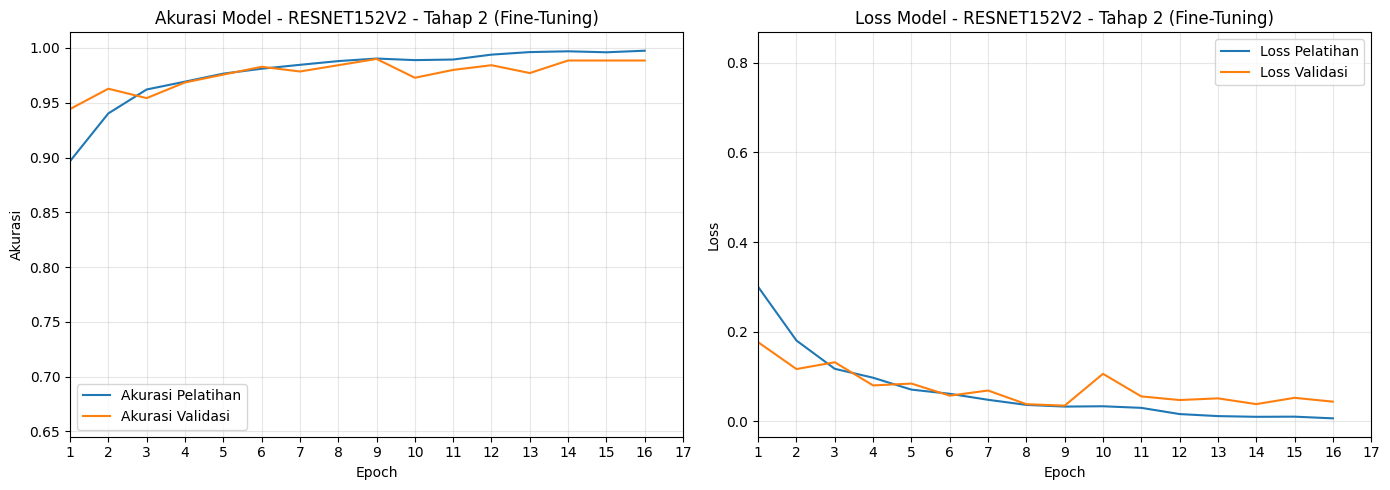

In [56]:
plot_history_training_resnet152v2_tahap_2 = evaluator.plot_history(
    history_resnet152v2_tahap_2,
    model_name="RESNET152V2 - Tahap 2 (Fine-Tuning)"
)

# Testing atau Evaluasi Model

## A. Membuat Class ModelEvaluator

Dalam class ModelEvaluator, terdapat beberapa method yang memiliki kegunaanya masing-masing, diantaranya adalah:
1. **Method __init__**, berguna untuk menginisialisasi atribut awal yang dibutuhkan dalam proses evaluasi model. Pada **method__init__**, terdapat dua atribut utama yang dibutuhkan, yakni:
* **self.class_names = class_names**, berguna untuk menyimpan daftar nama kelas yang digunakan dalam klasifikasi, seperti Busuk Buah, Helopeltis, Kakao Sehat dan Penggerek Buah Kakao. Daftar kelas ini digunakan untuk menampilkan nama kelas pada laporan klasifikasi dan confusion matrix.
* **self.results={}**, berguna untuk membuat dictionary kosong untuk menyimpan hasil evaluasi setiap model yang telah dievaluasi. Hasil tersebut nantinya digunakan dalam proses perbandingan performa model.
2. **method plot_history**, berguna untuk menampilkan grafik akurasi dan loss selama proses pelatihan model menggunakan data training dan data validasi. Method ini menerima dua parameter utama, yaitu **history** yang merupakan objek hasil dari proses model.fit() serta **model_name** yang digunakan untuk memberikan identitas model pada judul grafik. Sebelum menampilkan grafik, method ini memeriksa ketersediaan empat matrik, yaitu **accuracy**, **val_accuracy**, **loss** dan **val_loss**. Jika salah satu matrik tidak terpenuhi, maka code akan menghasilkan **ValueError**
3. **method predict**, berguna untuk menghasilkan prediksi model terhadap data yang terdapat dalam dataset sekaligus mengumpulkan label sebenarnya sebagai dasar evaluasi.
4. **method evaluate**, berguna untuk melakukan evaluasi menyeluruh terhadap performa model klasifikasi berdasarkan hasil prediksi pada dataset yang diberikan. Method ini menggunakan **method predict** untuk memperoleh label sebenarnya, label prediksi dan probabilitas prediksi. Selanjutnya, performa model dihitung menggunakan empat matrik evaluasi utama, diantaranya adalah:
* **Accuracy**: mengukur proporsi seluruh prediksi yang benar terhadap jumlah keseluruhan sampel.
* **Precision**: mengukur ketepatan prediksi pada setiap kelas, kemudian menggabungkannya menggunakan rata-rata berbobot (weighted average).
* **Recall**: mengukur kemampuan model dalam mengenali sampel dari kelas sebenarnya, kemudian menggabungkannya menggunakan rata-rata berbobot.
* **F1-Score**: mengukur keseimbangan antara precision dan recall menggunakan rata-rata berbobot.
* Selain keempat matrik tersebut, method ini juga menghasilkan classification report yang menyajikan precision, recall, F1-score, dan jumlah sampel (support) untuk setiap kelas. Method ini juga menghitung dua bentuk confusion matrix, yaitu:
* **Confusion Matrix**: menampilkan jumlah prediksi benar dan salah untuk setiap pasangan kelas sebenarnya dan kelas prediksi.
* **Normalized Confusion Matrix**: 

In [24]:
class ModelEvaluator:
    def __init__(self, class_names):
        """
        Parameters
        ----------
        class_names: list
            Daftar nama kelas sesuai urutan label.
        """
        self.class_names = class_names

        # Save hasil evaluasi setiap model
        self.results = {}

    # method plot training histroy model
    def plot_history(self, history, model_name="MODEL"):
        """
        Menampilkan grafik akurasi dan loss selama training.
        
        Parameters
        ----------
        history : keras.callbacks.History
            Objek history yang dikembalikan oleh model.fit().
        model_name : str
            Nama model yang ditampilkan pada judul grafik.
        """
        history_data = history.history

        # memastikan metrik yang dibutuhkan tersedia
        required_metrics = [
            "accuracy",
            "val_accuracy",
            "loss",
            "val_loss"
        ]

        missing_metrics = [
            metric for metric in required_metrics
            if metric not in history_data
        ]

        if missing_metrics:
            raise ValueError(f"Metrik berikut tidak ditemukan dalam history: {missing_metrics}")

        # membuat dua grafik, yaitu akurasi dan loss
        fig, axes = subplots(1, 2, figsize=(14, 5))

        # Grafik Akurasi
        axes[0].plot(history_data["accuracy"], label="Akurasi Pelatihan")
        axes[0].plot(history_data["val_accuracy"], label="Akurasi Validasi")
        axes[0].set_title(f"Akurasi Model - {model_name}")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Akurasi")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        # grafik loss
        axes[1].plot(history_data["loss"], label="Loss Pelatihan")
        axes[1].plot(history_data["val_loss"], label="Loss Validasi")
        axes[1].set_title(f"Loss Model - {model_name}")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Loss")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)

        # epoch dimulai dari 1
        for ax in axes:
            ax.set_xlim(left=1)
            ax.set_xticks(range(1, len(history_data["loss"]) + 1))

        tight_layout()
        show()

    # method prediction
    def predict(self, model, dataset):
        y_true = []
        y_prob = []
        
        for images, labels in dataset:
            predictions = model.predict(images, verbose=0)
            true_labels = argmax(labels.numpy(), axis=1)
            
            y_true.extend(true_labels)
            y_prob.extend(predictions)

        y_true = array(y_true)
        y_prob = array(y_prob)

        y_pred = argmax(y_prob, axis=1)

        return y_true, y_pred, y_prob

    # method evaluation
    def evaluate(self, model, dataset, model_name="MODEL", show_confusion_matrix=True):
        print("\n")
        print("=" * 70)
        print(f"EVALUASI MODEL: {model_name}")
        print("=" * 70)

        y_true, y_pred, y_prob = self.predict(model, dataset)

        # Metrics
        accuracy = accuracy_score(y_true, y_pred)
        precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
        recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
        f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

        # classification report
        report = classification_report(
            y_true, 
            y_pred, 
            labels=list(range(len(self.class_names))),
            target_names=self.class_names,
            zero_division=0
        )

        print("\nMETRICS")
        print("=" * 70)
        print(f"Accuracy : {accuracy * 100:.2f}%")
        print(f"Precision : {precision * 100:.2f}%")
        print(f"Recall : {recall * 100:.2f}%")
        print(f"F1-Score : {f1 * 100:.2f}%")

        print("\nCLASSIFICATION REPORT")
        print("=" * 70)
        print(report)

        # confusion matrix
        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=list(range(len(self.class_names)))
        )

        cm_normalized = divide(
            cm.astype("float"),
            cm.sum(axis=1, keepdims=True),
            out=zeros_like(cm, dtype=float),
            where=cm.sum(axis=1, keepdims=True) != 0
        )

        if show_confusion_matrix:
            fig, axes = subplots(1, 2, figsize=(16, 6))
            
            heatmap(
                cm, 
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=self.class_names,
                yticklabels=self.class_names,
                ax=axes[0]
            )
            axes[0].set_title(f"Confusion Matrix\n{model_name}")
            axes[0].set_xlabel("Predicted Label")
            axes[0].set_ylabel("True Label")

            heatmap(
                cm_normalized, 
                annot=True,
                fmt=".2f",
                cmap="Greens",
                xticklabels=self.class_names,
                yticklabels=self.class_names,
                ax=axes[1]
            )
            axes[1].set_title(f"Normalized Confusion Matrix\n{model_name}")
            axes[1].set_xlabel("Predicted Label")
            axes[1].set_ylabel("True Label")

            tight_layout()
            show()

        # menyimpan hasil evaluasi
        result = {
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "y_true": y_true,
            "y_pred": y_pred,
            "y_prob": y_prob,
            "confusion_matrix": cm,
            "normalized_confusion_matrix": cm_normalized,
            "classification_report": report
        }

        self.results[model_name] = result

        return result

    # method compare models
    def compare_models(self):
        if not self.results:
            print("Belum ada model yang telah dievaluasi.")
            return None

        comparison = []

        for model_name, result in self.results.items():
            comparison.append({
                "Model": model_name,
                "Accuracy (%)": result["Accuracy"] * 100,
                "Precision (%)": result["Precision"] * 100,
                "Recall (%)": result["Recall"] * 100,
                "F1-Score (%)": result["F1-Score"] * 100
            })

        comparison_df = pd.DataFrame(comparison)
        comparison_df = comparison_df.sort_values(by="Accuracy (%)", ascending=False).reset_index(drop=True)

        return comparison_df

In [25]:
class_names = [
    "Busuk Buah",
    "Helopeltis",
    "Kakao Sehat",
    "Penggerek Buah Kakao"
]

evaluator = ModelEvaluator(
    class_names=class_names
)

print("ModelEvaluator berhasil dibuat.")

ModelEvaluator berhasil dibuat.


## B. Evaluasi Model ResNet50-CBAM

#### Tahap 1

In [57]:
resnet50_cbam_tahap_1 = load_model(
    "best_resnet50_cbam_tahap_1.keras",
    custom_objects={
        "ConvolutionalBlockAttentionModule":
            ConvolutionalBlockAttentionModule
    }
)



EVALUASI MODEL: RESNET50-CBAM - Tahap 1

METRICS
Accuracy : 92.71%
Precision : 93.18%
Recall : 92.71%
F1-Score : 92.78%

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          Busuk Buah       0.95      0.89      0.92       175
          Helopeltis       0.94      0.93      0.93       175
         Kakao Sehat       0.85      0.97      0.90       175
Penggerek Buah Kakao       0.99      0.92      0.96       175

            accuracy                           0.93       700
           macro avg       0.93      0.93      0.93       700
        weighted avg       0.93      0.93      0.93       700



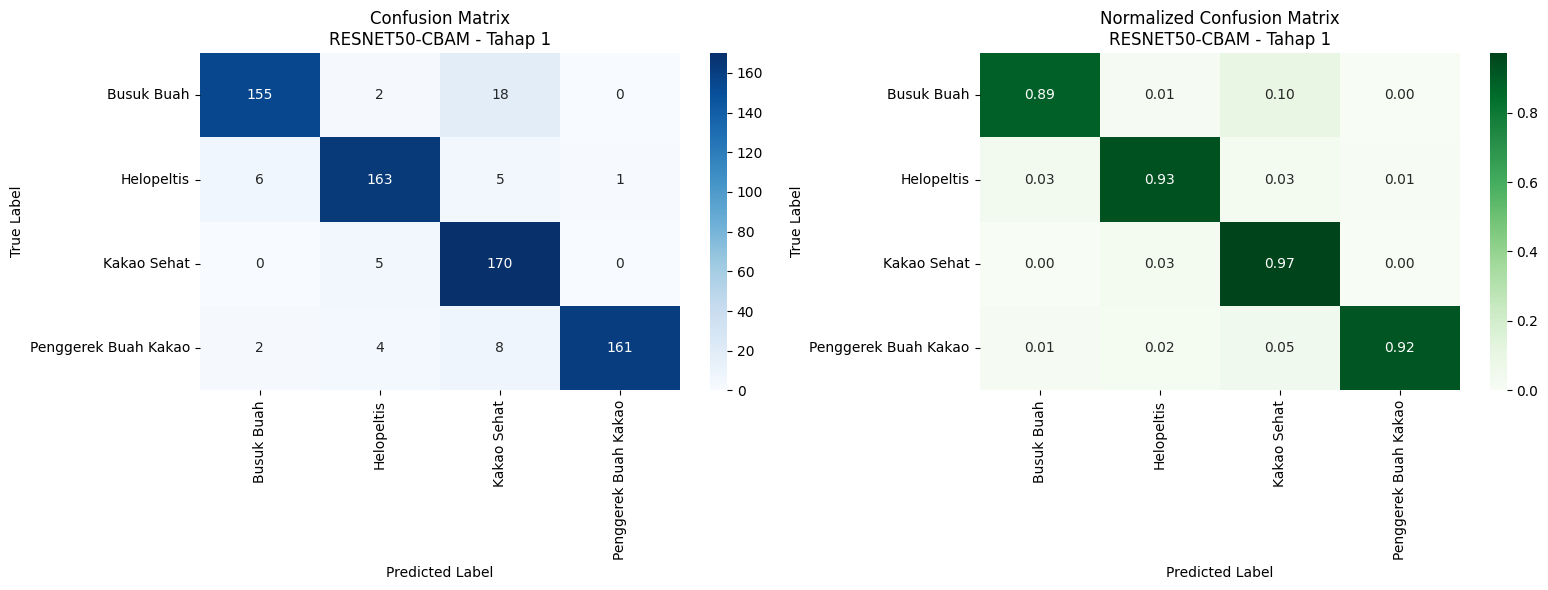

In [58]:
resnet50_cbam_tahap_1_result = evaluator.evaluate(
    model=resnet50_cbam_tahap_1,
    dataset=test_dataset_resnet50,
    model_name="RESNET50-CBAM - Tahap 1"
)

#### Tahap 2

In [59]:
resnet50_cbam_tahap_2 = load_model(
    "best_resnet50_cbam_tahap_2.keras",
    custom_objects={
        "ConvolutionalBlockAttentionModule":
            ConvolutionalBlockAttentionModule
    }
)



EVALUASI MODEL: RESNET50-CBAM - Tahap 2 (Fine-Tuning)

METRICS
Accuracy : 97.57%
Precision : 97.67%
Recall : 97.57%
F1-Score : 97.58%

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          Busuk Buah       0.98      0.98      0.98       175
          Helopeltis       0.99      0.95      0.97       175
         Kakao Sehat       0.94      1.00      0.97       175
Penggerek Buah Kakao       0.99      0.97      0.98       175

            accuracy                           0.98       700
           macro avg       0.98      0.98      0.98       700
        weighted avg       0.98      0.98      0.98       700



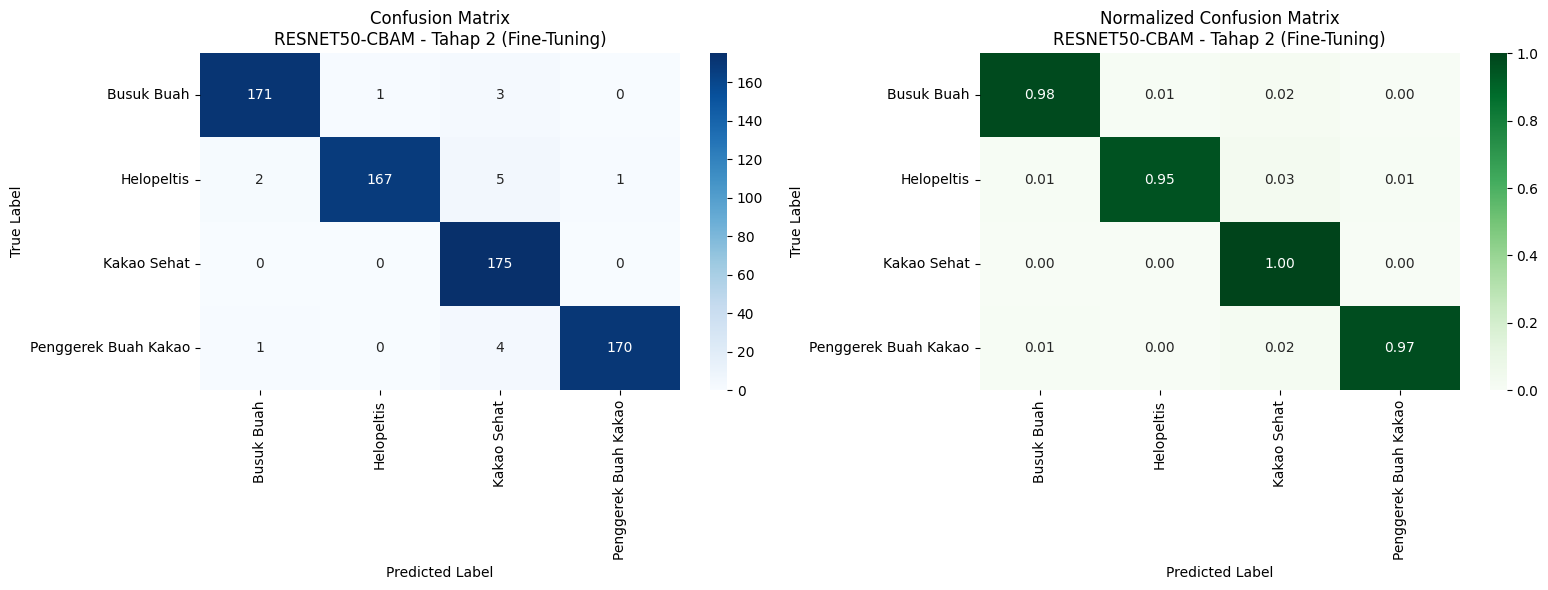

In [60]:
resnet50_cbam_tahap_2_result = evaluator.evaluate(
    model=resnet50_cbam_tahap_2,
    dataset=test_dataset_resnet50,
    model_name="RESNET50-CBAM - Tahap 2 (Fine-Tuning)"
)

## C. Evaluasi Model ResNet50

#### Tahap 1

In [61]:
resnet50_tahap_1 = load_model("best_resnet50_tahap_1.keras")



EVALUASI MODEL: RESNET50 - TAHAP 1

METRICS
Accuracy : 96.29%
Precision : 96.43%
Recall : 96.29%
F1-Score : 96.30%

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          Busuk Buah       0.98      0.98      0.98       175
          Helopeltis       0.92      0.99      0.95       175
         Kakao Sehat       0.97      0.95      0.96       175
Penggerek Buah Kakao       0.99      0.93      0.96       175

            accuracy                           0.96       700
           macro avg       0.96      0.96      0.96       700
        weighted avg       0.96      0.96      0.96       700



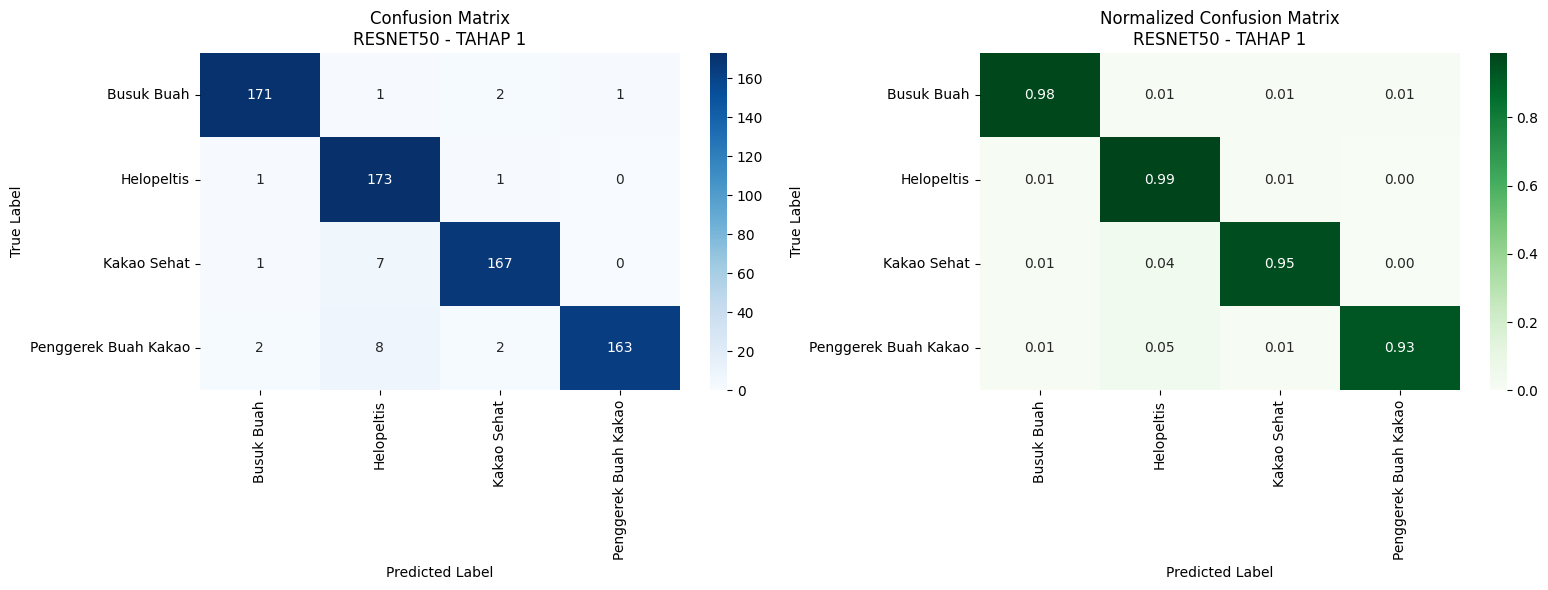

In [62]:
resnet50_tahap_1_result = evaluator.evaluate(
    model=resnet50_tahap_1,
    dataset=test_dataset_resnet50,
    model_name="RESNET50 - TAHAP 1"
)

#### Tahap 2

In [63]:
resnet50_tahap_2 = load_model("best_resnet50_tahap_2.keras")



EVALUASI MODEL: RESNET50 - TAHAP 2

METRICS
Accuracy : 98.00%
Precision : 98.01%
Recall : 98.00%
F1-Score : 98.00%

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          Busuk Buah       0.99      0.98      0.99       175
          Helopeltis       0.98      0.98      0.98       175
         Kakao Sehat       0.97      0.99      0.98       175
Penggerek Buah Kakao       0.99      0.97      0.98       175

            accuracy                           0.98       700
           macro avg       0.98      0.98      0.98       700
        weighted avg       0.98      0.98      0.98       700



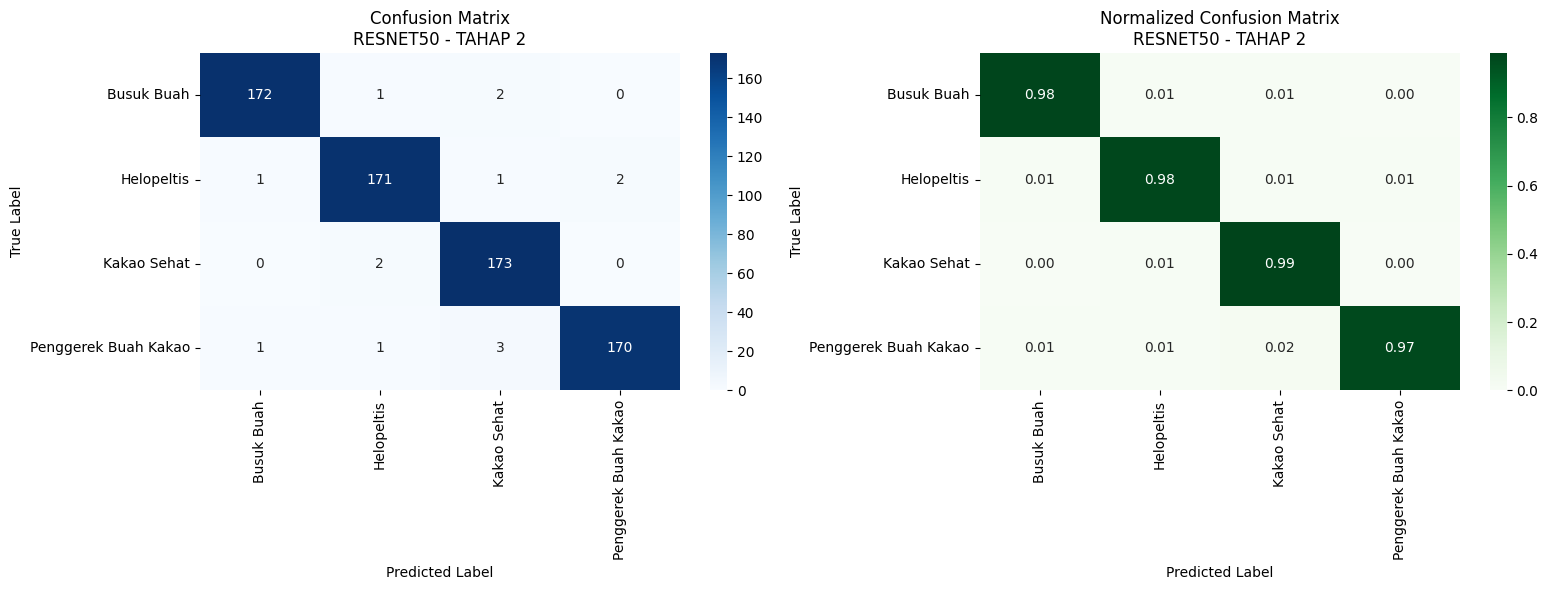

In [64]:
resnet50_tahap_2_result = evaluator.evaluate(
    model=resnet50_tahap_2,
    dataset=test_dataset_resnet50,
    model_name="RESNET50 - TAHAP 2"
)

## D. Evaluasi Model ResNet152V2

#### Tahap 1

In [65]:
resnet152v2_tahap_1 = load_model("best_resnet152v2_tahap_1.keras")



EVALUASI MODEL: RESNET152V2 - TAHAP 1

METRICS
Accuracy : 94.00%
Precision : 94.34%
Recall : 94.00%
F1-Score : 93.99%

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          Busuk Buah       0.98      0.94      0.96       175
          Helopeltis       0.88      0.98      0.93       175
         Kakao Sehat       0.93      0.98      0.95       175
Penggerek Buah Kakao       0.98      0.87      0.92       175

            accuracy                           0.94       700
           macro avg       0.94      0.94      0.94       700
        weighted avg       0.94      0.94      0.94       700



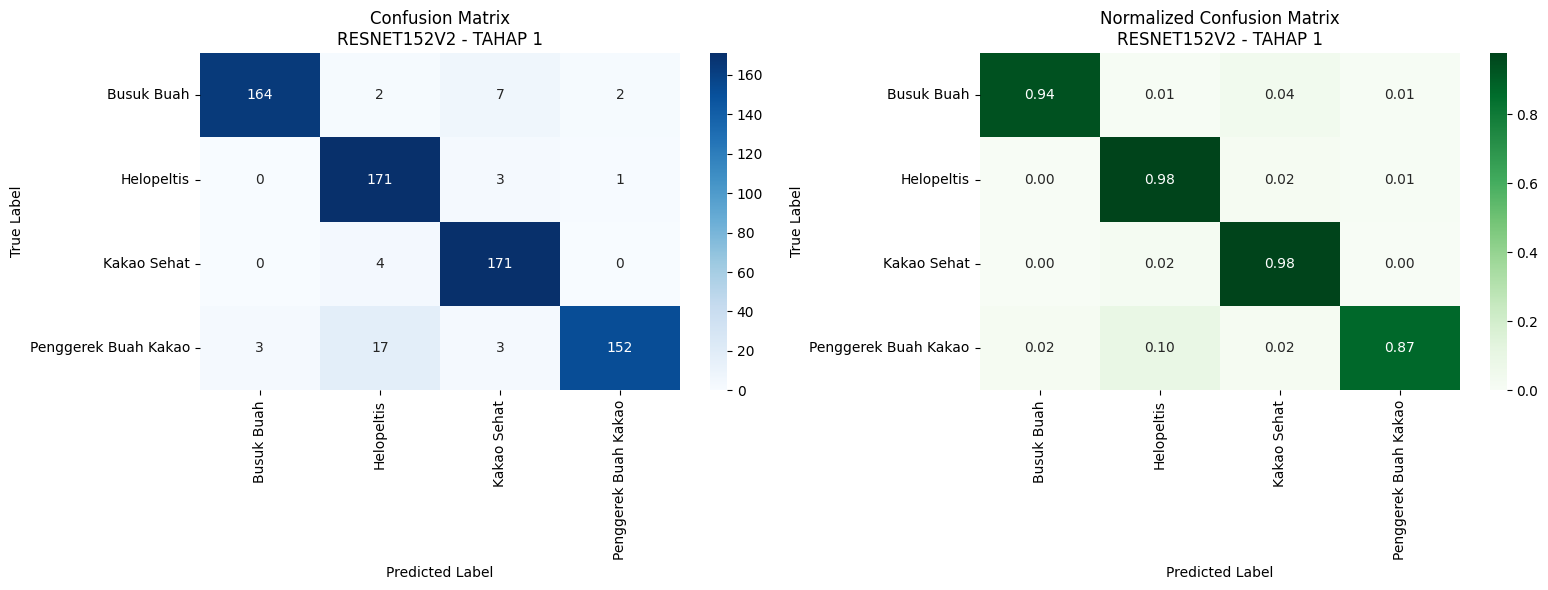

In [66]:
resnet152v2_tahap_1_result = evaluator.evaluate(
    model=resnet152v2_tahap_1,
    dataset=test_dataset_resnet152v2,
    model_name="RESNET152V2 - TAHAP 1"
)

#### Tahap 2

In [67]:
resnet152v2_tahap_2 = load_model("best_resnet152v2_tahap_2.keras")



EVALUASI MODEL: RESNET152V2 - TAHAP 2

METRICS
Accuracy : 97.57%
Precision : 97.59%
Recall : 97.57%
F1-Score : 97.57%

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          Busuk Buah       0.99      0.98      0.98       175
          Helopeltis       0.97      0.97      0.97       175
         Kakao Sehat       0.96      0.98      0.97       175
Penggerek Buah Kakao       0.99      0.98      0.98       175

            accuracy                           0.98       700
           macro avg       0.98      0.98      0.98       700
        weighted avg       0.98      0.98      0.98       700



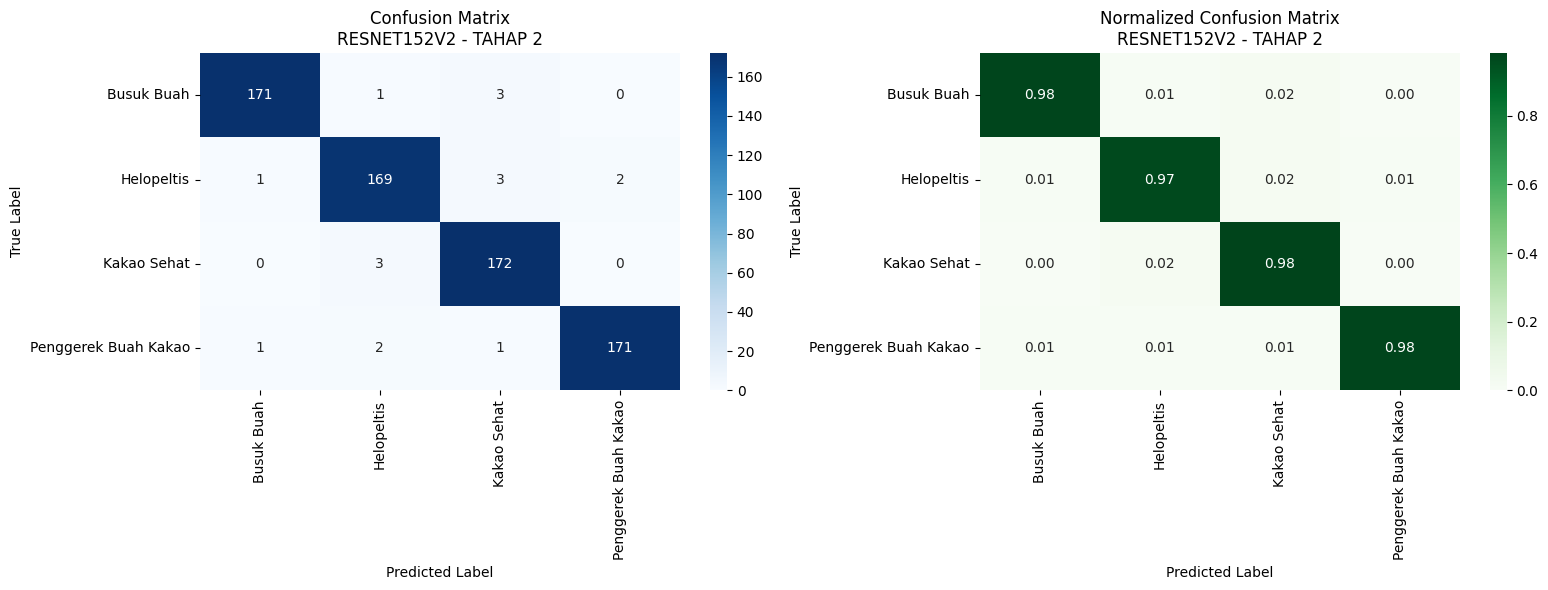

In [68]:
resnet152v2_tahap_2_result = evaluator.evaluate(
    model=resnet152v2_tahap_2,
    dataset=test_dataset_resnet152v2,
    model_name="RESNET152V2 - TAHAP 2"
)

# Comparison

In [69]:
comparison_df = evaluator.compare_models()
display(comparison_df)

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,RESNET50 - TAHAP 2,98.000000,98.012529,98.000000,98.001111
1,RESNET50-CBAM - Tahap 2 (Fine-Tuning),97.571429,97.669679,97.571429,97.580335
2,RESNET152V2 - TAHAP 2,97.571429,97.587169,97.571429,97.574573
3,RESNET50 - TAHAP 1,96.285714,96.432986,96.285714,96.297006
4,RESNET152V2 - TAHAP 1,94.000000,94.336805,94.000000,93.993799
5,RESNET50-CBAM - Tahap 1,92.714286,93.182504,92.714286,92.775053
